# F1 Podium Prediction – Milestone 1

**Team 28**

| Name | ID | Tutorial |
|---|---|---|
| Ali Abuelkheir | 58-3693 | T17 |
| Maria Awad | 58-5927 | T28 |
| Rodaina Elsawy | 58-16542 | T24 |
| Monica Samaan | 58-4467 | T18 |

For every driver in every race we predict: **will this driver finish on the podium (`positionOrder <= 3`)?** We only use what is known **after qualifying and before the race starts**. Results, points, status, laps, pit stops and post-race standings of the same race are leakage.

Dataset: Formula 1 World Championship (1950–2024), Kaggle / Ergast, 14 linked CSV tables.

**Contents**

1. Setup
2. Audit (EDA before cleaning)
3. Cleaning
4. EDA after cleaning
5. Base table for the questions
6. Q1 – Front row to podium per circuit
7. Q2 – Home advantage, controlled for grid
8. Q3 – Mechanical retirements per constructor
9. Target and features
10. Pre-processing
11. Metrics
12. Models
13. Evaluation
14. Pre-processing order experiments
15. Explainability
16. Inference function
17. Summary and limitations

The data is cleaned **once** (section 3). The questions, the features and the experiments all start from that cleaned table. The notebook runs top to bottom with Run All; on Kaggle the paths are found automatically.

## 1. Setup

### 1.1 Imports and paths

In [1]:
import os
import glob
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # hide TensorFlow info messages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score, precision_recall_curve
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

import keras
from keras import layers
import shap
from lime.lime_tabular import LimeTabularExplainer

pd.set_option('display.max_rows', 100)
sns.set_theme(style='whitegrid')

DATA_DIR = '../data/raw'        # raw CSVs, only read
OUT_DIR = '../data/processed'   # the modeling table is saved here

# on Kaggle: use the attached dataset folder that has results.csv
if os.path.exists('/kaggle/input'):
    DATA_DIR = os.path.dirname(glob.glob('/kaggle/input/**/results.csv', recursive=True)[0])
    OUT_DIR = '/kaggle/working'

DATA_DIR

'../data/raw'

### 1.2 Load the 14 tables

The raw files are never changed. We clean the copies in memory.

In [2]:
names = ['circuits', 'constructors', 'constructor_results', 'constructor_standings', 'drivers', 'driver_standings',
         'lap_times', 'pit_stops', 'qualifying', 'races', 'results', 'seasons', 'sprint_results', 'status']
tables = {name: pd.read_csv(DATA_DIR + '/' + name + '.csv') for name in names}

pd.Series({name: len(df) for name, df in tables.items()})

circuits                     77
constructors                212
constructor_results       12625
constructor_standings     13391
drivers                     861
driver_standings          34863
lap_times                589081
pit_stops                 11371
qualifying                10494
races                      1125
results                   26759
seasons                      75
sprint_results              360
status                      139
dtype: int64

Short names for the tables we use.

In [3]:
results = tables['results']
races = tables['races']
qualifying = tables['qualifying']
drivers = tables['drivers']
circuits = tables['circuits']
status = tables['status']
driver_standings = tables['driver_standings']
constructor_standings = tables['constructor_standings']
constructors = tables['constructors']

## 2. Audit (EDA before cleaning)

### 2.1 Column names and stray spaces

In our copy, two tables have spaces around their column names and text values (`' raceId'` instead of `raceId`), so a merge would fail.

In [4]:
print(tables['constructor_standings'].columns.tolist())
print(tables['constructor_standings'].iloc[0].tolist())

['constructorStandingsId', ' raceId', ' constructorId', ' points', ' position', ' positionText', ' wins']
[np.int64(1), np.int64(18), np.int64(1), np.float64(14.0), np.int64(1), ' "1"         ', np.int64(1)]


We strip the spaces (and quotes). Where there are none, nothing changes.

In [5]:
for df in tables.values():
    df.columns = df.columns.str.strip()

tables['constructor_results']['status'] = tables['constructor_results']['status'].str.strip().str.strip('"')
tables['constructor_standings']['positionText'] = tables['constructor_standings']['positionText'].str.strip().str.strip('"')

print(tables['constructor_standings'].columns.tolist())
print(tables['constructor_standings'].iloc[0].tolist())

['constructorStandingsId', 'raceId', 'constructorId', 'points', 'position', 'positionText', 'wins']
[np.int64(1), np.int64(18), np.int64(1), np.float64(14.0), np.int64(1), '1', np.int64(1)]


### 2.2 Sentinels

A sentinel is a placeholder written where a value is missing. Here it is the text `\N`. Pandas does not see it as missing, so we count it in every column of every table.

In [6]:
rows = []
for name, df in tables.items():
    counts = (df == '\\N').sum()
    for col in counts[counts > 0].index:
        rows.append([name + '.' + col, counts[col], round(counts[col] / len(df), 3)])

sentinels = pd.DataFrame(rows, columns=['column', 'n_sentinel', 'share'])
sentinels

,column,n_sentinel,share
0,constructor_results.status,12608,0.999
1,drivers.number,802,0.931
2,drivers.code,757,0.879
3,qualifying.q1,156,0.015
4,qualifying.q2,4625,0.441
5,qualifying.q3,6819,0.650
6,races.time,731,0.650
7,races.fp1_date,1035,0.920
8,races.fp1_time,1057,0.940
9,races.fp2_date,1035,0.920


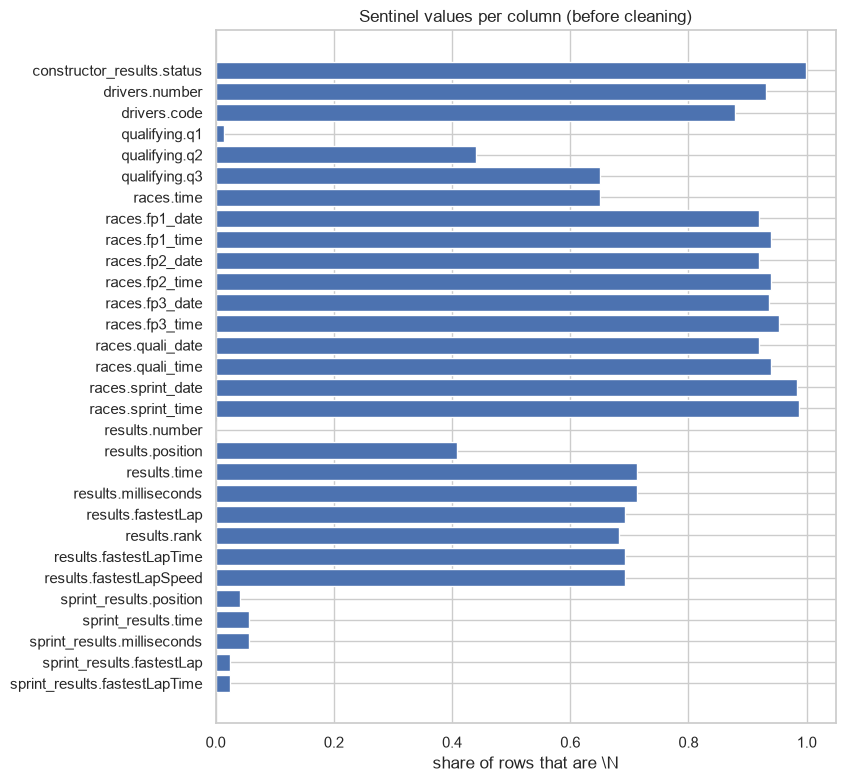

In [7]:
plt.figure(figsize=(8, 9))
plt.barh(sentinels['column'], sentinels['share'])
plt.xlabel('share of rows that are \\N')
plt.title('Sentinel values per column (before cleaning)')
plt.gca().invert_yaxis()
plt.show()

Six tables have sentinels. They make sense: `results.position` is `\N` when the driver was not classified, and `q2`/`q3` are `\N` for drivers knocked out earlier.

There is a second kind of missing value: cells that are just empty. Pandas already reads those as `NaN`.

In [8]:
qualifying.isna().sum()

qualifyId         0
raceId            0
driverId          0
constructorId     0
number            0
position          0
q1                0
q2               22
q3               46
dtype: int64

### 2.3 Primary keys

A primary key identifies one row. It must have no repeated and no empty value.

In [9]:
primary_keys = {
    'circuits': ['circuitId'], 'constructors': ['constructorId'], 'constructor_results': ['constructorResultsId'],
    'constructor_standings': ['constructorStandingsId'], 'drivers': ['driverId'],
    'driver_standings': ['driverStandingsId'], 'lap_times': ['raceId', 'driverId', 'lap'],
    'pit_stops': ['raceId', 'driverId', 'stop'], 'qualifying': ['qualifyId'], 'races': ['raceId'],
    'results': ['resultId'], 'seasons': ['year'], 'sprint_results': ['resultId'], 'status': ['statusId'],
}

rows = []
for name, key in primary_keys.items():
    rows.append([name, key, tables[name].duplicated(key).sum(), tables[name][key].isna().sum().sum()])

pd.DataFrame(rows, columns=['table', 'primary_key', 'duplicates', 'nulls'])

,table,primary_key,duplicates,nulls
0,circuits,[circuitId],0,0
1,constructors,[constructorId],0,0
2,constructor_results,[constructorResultsId],0,0
3,constructor_standings,[constructorStandingsId],0,0
4,drivers,[driverId],0,0
5,driver_standings,[driverStandingsId],0,0
6,lap_times,"[raceId, driverId, lap]",0,0
7,pit_stops,"[raceId, driverId, stop]",0,0
8,qualifying,[qualifyId],0,0
9,races,[raceId],0,0


### 2.4 Foreign keys

A foreign key points at another table. We count the values that do not exist in the parent table (orphans).

In [10]:
foreign_keys = [
    ('races', 'circuitId', 'circuits'), ('races', 'year', 'seasons'),
    ('results', 'raceId', 'races'), ('results', 'driverId', 'drivers'),
    ('results', 'constructorId', 'constructors'), ('results', 'statusId', 'status'),
    ('qualifying', 'raceId', 'races'), ('qualifying', 'driverId', 'drivers'),
    ('qualifying', 'constructorId', 'constructors'),
    ('sprint_results', 'raceId', 'races'), ('sprint_results', 'driverId', 'drivers'),
    ('sprint_results', 'constructorId', 'constructors'), ('sprint_results', 'statusId', 'status'),
    ('driver_standings', 'raceId', 'races'), ('driver_standings', 'driverId', 'drivers'),
    ('constructor_standings', 'raceId', 'races'), ('constructor_standings', 'constructorId', 'constructors'),
    ('constructor_results', 'raceId', 'races'), ('constructor_results', 'constructorId', 'constructors'),
    ('lap_times', 'raceId', 'races'), ('lap_times', 'driverId', 'drivers'),
    ('pit_stops', 'raceId', 'races'), ('pit_stops', 'driverId', 'drivers'),
]

rows = []
for child, col, parent in foreign_keys:
    rows.append([child, col, parent, (~tables[child][col].isin(tables[parent][col])).sum()])

pd.DataFrame(rows, columns=['table', 'column', 'points_to', 'orphans'])

,table,column,points_to,orphans
0,races,circuitId,circuits,0
1,races,year,seasons,0
2,results,raceId,races,0
3,results,driverId,drivers,0
4,results,constructorId,constructors,0
5,results,statusId,status,0
6,qualifying,raceId,races,0
7,qualifying,driverId,drivers,0
8,qualifying,constructorId,constructors,0
9,sprint_results,raceId,races,0


### 2.5 The modeling key

All 14 primary keys are unique and complete, and all 23 links have no orphans. Our table needs one row per (`raceId`, `driverId`). Is that pair unique in `results`?

In [11]:
results.duplicated(['raceId', 'driverId']).sum()

np.int64(91)

No. Some drivers appear more than once in a race. We fix this in section 3.4.

### 2.6 Rows and podium rate per season

We add the year and race name to a copy of `results`, and keep two series to compare after cleaning.

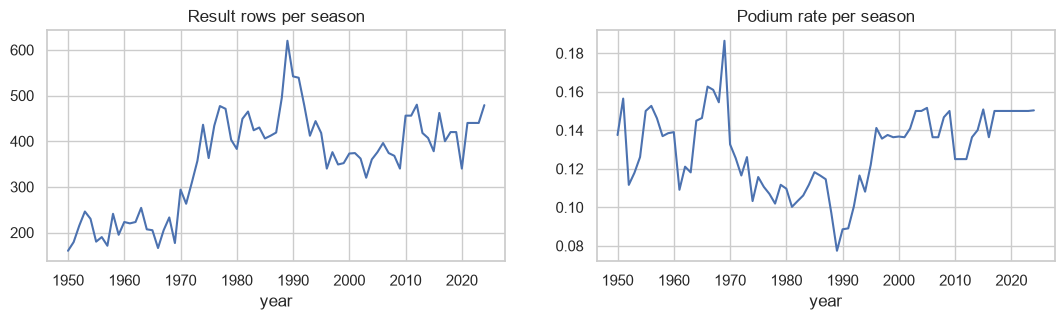

In [12]:
eda = results.merge(races[['raceId', 'year', 'name']], on='raceId')
eda['podium'] = eda['positionOrder'] <= 3

rows_before = eda.groupby('year').size()
podium_before = eda.groupby('year')['podium'].mean()

fig, ax = plt.subplots(1, 2, figsize=(13, 3))
rows_before.plot(ax=ax[0], title='Result rows per season')
podium_before.plot(ax=ax[1], title='Podium rate per season')
plt.show()

Rows per season are not steady: the late 1980s and early 1990s have many more entries. The podium rate drops in those years, because every race has about three podiums whatever the number of rows.

### 2.7 `positionText` codes and grid 0

`positionText` says why a driver has no position.

In [13]:
eda['positionText'][~eda['positionText'].str.isdigit()].value_counts()

positionText
R    8897
F    1368
W     336
N     190
D     151
E       9
Name: count, dtype: int64

`R` = retired, `F` = failed to qualify, `W` = withdrew, `N` = not classified, `D` = disqualified, `E` = excluded (FastF1 documentation, which wraps the Ergast API). `F` and `W` drivers never started, which explains the extra rows of the 1980s and 1990s.

`position` is empty for these letters. `positionOrder` is never empty: it ranks every row of a race, so retired drivers also get a number. That is why the podium is defined as `positionOrder <= 3`.

rows with grid 0: 1638


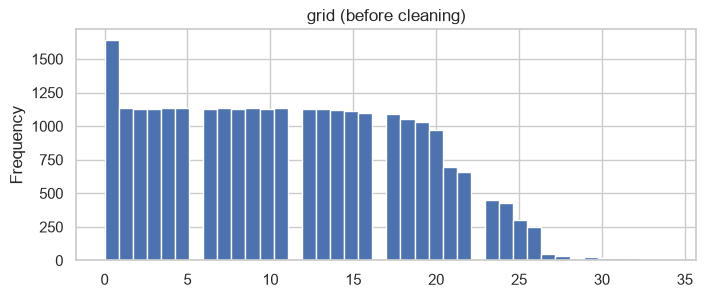

In [14]:
print('rows with grid 0:', (eda['grid'] == 0).sum())

eda['grid'].plot(kind='hist', bins=40, figsize=(8, 3), title='grid (before cleaning)')
plt.show()

`grid` has a spike at 0, which is not a real starting position. Most of these rows are drivers who never started; we look at the rest in section 3.6.

### 2.8 Qualifying coverage

How many races have qualifying data?

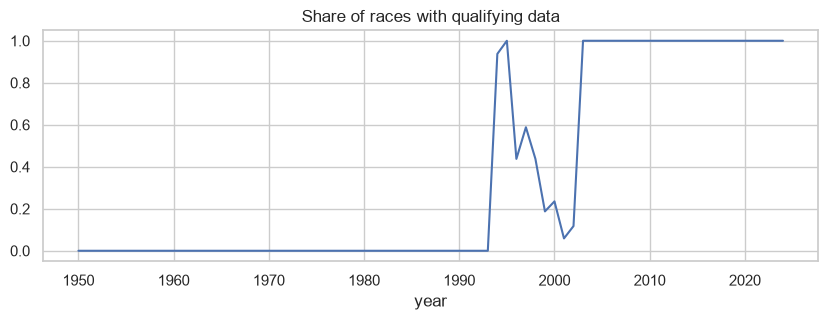

In [15]:
races['raceId'].isin(qualifying['raceId']).groupby(races['year']).mean().plot(figsize=(10, 3), title='Share of races with qualifying data')
plt.show()

Qualifying data starts in 1994, is patchy from 1996 to 2002, and is complete from 2003. This is the *qualifying-coverage drift* MS1 warns about.

### 2.9 Indianapolis 500

The Indianapolis 500 was part of the championship from 1950 to 1960.

In [16]:
indy = eda[eda['name'] == 'Indianapolis 500']
others = eda[(eda['name'] != 'Indianapolis 500') & (eda['year'] <= 1960)]

print('rows:', len(indy), '| races:', indy['raceId'].nunique(), '| drivers:', indy['driverId'].nunique())
print('drivers who also raced elsewhere:', indy[indy['driverId'].isin(others['driverId'])]['driverId'].nunique())

rows: 405 | races: 11 | drivers: 107
drivers who also raced elsewhere: 3


Almost none of the Indianapolis drivers raced anywhere else. It is nearly a separate set of drivers.

## 3. Cleaning

### 3.1 Sentinels to missing

Replace `\N` with a real missing value in every table, then count again.

In [17]:
for df in tables.values():
    df.replace('\\N', np.nan, inplace=True)

sum((df == '\\N').sum().sum() for df in tables.values())

np.int64(0)

### 3.2 Types and stray spaces

The columns that had `\N` are still text, and dates are text too.

In [18]:
num_cols = ['number', 'position', 'milliseconds', 'fastestLap', 'rank', 'fastestLapSpeed']
print(results[num_cols].dtypes.tolist(), races['date'].dtype, drivers['dob'].dtype)

[<StringDtype(na_value=nan)>, <StringDtype(na_value=nan)>, <StringDtype(na_value=nan)>, <StringDtype(na_value=nan)>, <StringDtype(na_value=nan)>, <StringDtype(na_value=nan)>] str str


In [19]:
results[num_cols] = results[num_cols].apply(pd.to_numeric)
races['date'] = pd.to_datetime(races['date'])
drivers['dob'] = pd.to_datetime(drivers['dob'])

print(results[num_cols].dtypes.tolist(), races['date'].dtype, drivers['dob'].dtype)

[dtype('float64'), dtype('float64'), dtype('float64'), dtype('float64'), dtype('float64'), dtype('float64')] datetime64[us] datetime64[us]


One nationality has a space around it. Q2 matches nationality to a country, so the text must be exact.

In [20]:
print((drivers['nationality'] != drivers['nationality'].str.strip()).sum())

drivers['nationality'] = drivers['nationality'].str.strip()

1


### 3.3 Lap times to seconds

Qualifying lap times are text like `1:26.572`. Adding `00:` in front makes it hours:minutes:seconds, which pandas can read as a duration.

The other duration columns are all post-race (`results.time`, `results.fastestLapTime`, `lap_times.time`, `pit_stops.duration`) and are never used. Race time, lap times and pit-stop times already have a numeric `milliseconds` column next to the text, so we leave the text copies as they are.

In [21]:
for col in ['q1', 'q2', 'q3']:
    qualifying[col + '_sec'] = pd.to_timedelta('00:' + qualifying[col]).dt.total_seconds()

qualifying[['q1', 'q1_sec', 'q2', 'q2_sec', 'q3', 'q3_sec']].describe().loc[['count', 'min', 'max']]

,q1_sec,q2_sec,q3_sec
count,10338.000,5847.000,3629.000
min,53.904,53.647,53.377
max,1002.640,132.470,129.776


The largest `q1_sec` is about 1000 seconds, more than 16 minutes. We look at the slowest laps.

In [22]:
qualifying.nlargest(4, 'q1_sec')[['raceId', 'driverId', 'position', 'q1', 'q1_sec']]

,raceId,driverId,position,q1,q1_sec
2567,255,87,24,16:42.640,1002.640
2853,267,113,26,2:33.885,153.885
2852,267,111,25,2:31.755,151.755
2851,267,104,24,2:30.931,150.931


One value is far from all the others. It is a data error, so we set it to missing. The other slow laps are possible (a wet session), so they stay.

In [23]:
qualifying.loc[qualifying['q1_sec'] > 600, 'q1_sec'] = np.nan

### 3.4 Duplicates: one driver, several rows in a race

rows involved: 176 | driver-race pairs: 85 | rows to drop: 91


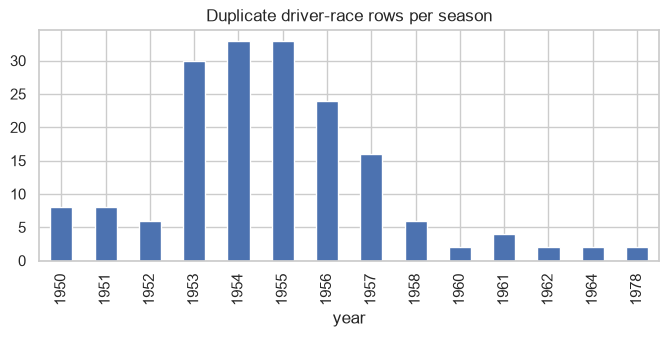

In [24]:
key = ['raceId', 'driverId']
dups = results[results.duplicated(key, keep=False)].merge(races[['raceId', 'year', 'name']], on='raceId')

print('rows involved:', len(dups), '| driver-race pairs:', len(dups.drop_duplicates(key)), '| rows to drop:', results.duplicated(key).sum())

dups.groupby('year').size().plot(kind='bar', figsize=(8, 3), title='Duplicate driver-race rows per season')
plt.show()

Almost all are from the 1950s and early 1960s. These are **shared drives**: a driver could take over a teammate's car during the race, so he has one row per car.

**Rule: keep the row with the best (lowest) `positionOrder`.** The row answers "did this driver finish on the podium?", and a podium in a shared car is an official podium for that driver.

Limitation: the kept row can carry the grid of the car the driver took over, not the car he started in. The data does not say which car he started in.

In [25]:
n_raw = len(results)
results = results.sort_values('positionOrder').drop_duplicates(key)
n_dedup = len(results)

print(n_raw, '->', n_dedup, '| duplicates left:', results.duplicated(key).sum())

26759 -> 26668 | duplicates left: 0


The opposite case also exists: **two drivers sharing one car**. Both get the car's finishing position, so a few races have more than three podium rows.

In [26]:
results[results['positionOrder'] <= 3].groupby('raceId').size().value_counts().sort_index()

3    1107
4      16
5       2
Name: count, dtype: int64

We keep these rows. Each driver appears once, and both were officially on the podium.

### 3.5 Drop Indianapolis 500 and drivers who never started

`df` is the cleaned results with the race information and the status text. We remove:

- the **Indianapolis 500** (a separate set of drivers on a very different track),
- drivers who **never started**: `F` (failed to qualify) and `W` (withdrew). After qualifying we already know they are out.

In [27]:
race_cols = races[['raceId', 'year', 'round', 'date', 'name', 'circuitId']].rename(columns={'name': 'race_name'})
df = results.merge(race_cols, on='raceId').merge(status, on='statusId')

df = df[df['race_name'] != 'Indianapolis 500']
n_indy = len(df)

df = df[~df['positionText'].isin(['F', 'W'])]
n_fw = len(df)

print(n_dedup, '->', n_indy, '->', n_fw)

26668 -> 26287 -> 24586


### 3.6 Grid 0

What is left with `grid` 0, and did those drivers complete any lap?

In [28]:
zero = df[df['grid'] == 0]
pd.crosstab(zero['year'] >= 2015, zero['laps'] > 0, rownames=['2015 or later'], colnames=['did laps'])

did laps,False,True
2015 or later,,
False,14,0
True,1,72


In [29]:
zero[zero['laps'] == 0]['status'].value_counts()

status
Excluded        6
Disqualified    6
Battery         1
Underweight     1
Retired         1
Name: count, dtype: int64

Two groups:

- **0 laps**: excluded or disqualified before the race, or the car failed before the start. They did not start, so we remove them too.
- **Did laps**: **pit-lane starts**. The car starts behind the whole grid. Left as 0, the model would read it as better than pole, so we replace 0 with **last grid place in that race + 1**. We keep a `pit_lane_start` flag first, because Q2 needs to know which starts had no grid slot.

In [30]:
df = df[~((df['grid'] == 0) & (df['laps'] == 0))]
n_clean = len(df)

df['pit_lane_start'] = (df['grid'] == 0).astype(int)
last_place = df.groupby('raceId')['grid'].transform('max')
df['grid'] = df['grid'].where(df['grid'] > 0, last_place + 1)

print(n_fw, '->', n_clean, '| pit-lane starts:', df['pit_lane_start'].sum(), '| grid 0 left:', (df['grid'] == 0).sum())

24586 -> 24571 | pit-lane starts: 72 | grid 0 left: 0


## 4. EDA after cleaning

### 4.1 Rows after each step

raw                26759
duplicates         26668
Indianapolis       26287
F and W            24586
grid 0, no laps    24571
dtype: int64


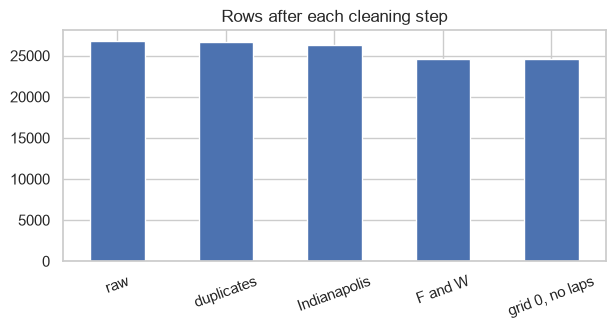

In [31]:
steps = pd.Series({'raw': n_raw, 'duplicates': n_dedup, 'Indianapolis': n_indy, 'F and W': n_fw, 'grid 0, no laps': n_clean})
print(steps)

steps.plot(kind='bar', figsize=(7, 3), title='Rows after each cleaning step')
plt.xticks(rotation=20)
plt.show()

### 4.2 Before vs after

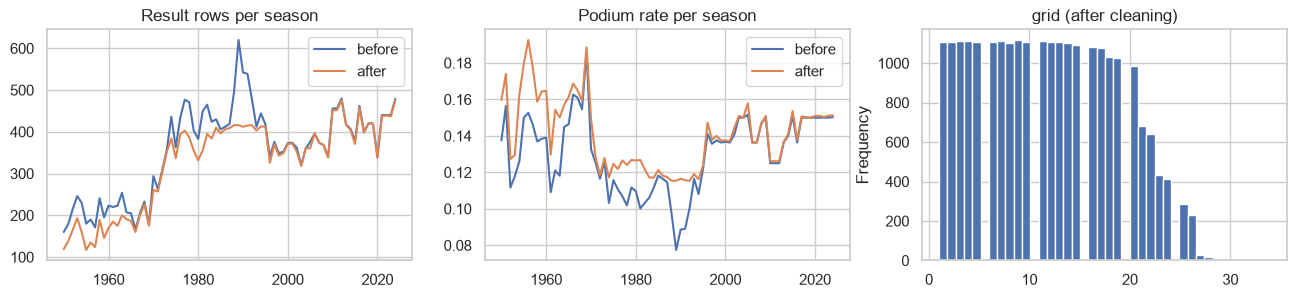

In [32]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3))
ax[0].plot(rows_before, label='before')
ax[0].plot(df.groupby('year').size(), label='after')
ax[0].set_title('Result rows per season')
ax[0].legend()
ax[1].plot(podium_before, label='before')
ax[1].plot((df['positionOrder'] <= 3).groupby(df['year']).mean(), label='after')
ax[1].set_title('Podium rate per season')
ax[1].legend()
df['grid'].plot(kind='hist', bins=40, ax=ax[2], title='grid (after cleaning)')
plt.show()

- The bump of the late 1980s and early 1990s is much smaller: most of those rows were drivers who never started.
- The seasons with the lowest podium rate move up, for the same reason.
- The spike at grid 0 is gone.

## 5. Base table for the questions

### 5.1 Cleaned table + circuits, constructors and qualifying

The questions start from the cleaned `df`, so they use the same rows as the model: one row per driver per race, only drivers who started. We add the circuit name and country, the constructor name and the qualifying position (left join, so a start without a qualifying row is kept). The row count must not change.

In [33]:
circuits_small = circuits[['circuitId', 'name', 'country']].rename(columns={'name': 'circuit'})
constructors_small = constructors[['constructorId', 'name']].rename(columns={'name': 'constructor'})
quali_small = qualifying[['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'})

merged = df.merge(circuits_small, on='circuitId').merge(constructors_small, on='constructorId')
merged = merged.merge(quali_small, on=['raceId', 'driverId'], how='left')
merged['podium'] = (merged['positionOrder'] <= 3).astype(int)

len(df), len(merged)

(24571, 24571)

In [34]:
merged[['raceId', 'year', 'race_name', 'circuit', 'country', 'driverId', 'constructor', 'grid', 'quali_pos', 'positionOrder', 'podium']].head()

,raceId,year,race_name,circuit,country,driverId,constructor,grid,quali_pos,positionOrder,podium
0,500,1980,South African Grand Prix,Kyalami,South Africa,163,Renault,2,NaN,1,1
1,20,2008,Bahrain Grand Prix,Bahrain International Circuit,Bahrain,13,Ferrari,2,2.0,1,1
2,1144,2024,Abu Dhabi Grand Prix,Yas Marina Circuit,UAE,846,McLaren,1,1.0,1,1
3,405,1986,Spanish Grand Prix,Circuito de Jerez,Spain,102,Team Lotus,1,NaN,1,1
4,232,1996,French Grand Prix,Circuit de Nevers Magny-Cours,France,71,Williams,2,NaN,1,1


---
## 6. Q1 – Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?

### 6.1 Plan and years

- **Unit (grain):** one front-row starter in one race.
- **Conversion rate of a circuit** = podiums of its front-row starters / number of its front-row starters.
- **Two definitions of "front row"**, because they can differ after penalties:
  - by **grid**: `grid` is 1 or 2 (where the car really started);
  - by **qualifying**: `quali_pos` is 1 or 2 (the result of the session, before penalties).
- **Joins (multi-hop):** `results → races` (year), `races → circuits` (circuit), `results → qualifying` (qualifying position), all in the base table.

Before choosing the years we check, per season, how many starters have a qualifying row.

In [35]:
coverage = merged['quali_pos'].notna().groupby(merged['year']).mean()
coverage[coverage.index >= 1992].round(3)

year
1992    0.000
1993    0.000
1994    0.942
1995    1.000
1996    0.448
1997    0.589
1998    0.434
1999    0.183
2000    0.237
2001    0.059
2002    0.116
2003    1.000
2004    1.000
2005    1.000
2006    1.000
2007    1.000
2008    1.000
2009    1.000
2010    1.000
2011    0.991
2012    0.994
2013    1.000
2014    0.995
2015    0.995
2016    0.989
2017    0.995
2018    1.000
2019    0.995
2020    1.000
2021    0.998
2022    1.000
2023    1.000
2024    1.000
Name: quali_pos, dtype: float64

Same picture as section 2.8: no qualifying data before 1994, mostly missing in 1996–2002, complete from 2003. This matches the Ergast note that qualifying is fully supported from 2003.

**Decision: use 2003–2024**, so both definitions exist on the same races. This gives two eras of 11 seasons each: **2003–2013** and **2014–2024**.

In [36]:
q1 = merged[merged['year'] >= 2003].copy()
q1['era'] = '2003-2013'
q1.loc[q1['year'] >= 2014, 'era'] = '2014-2024'

print(len(q1), 'starts |', q1['quali_pos'].isna().sum(), 'without a qualifying row')
q1.groupby('era')['raceId'].nunique()

8909 starts | 21 without a qualifying row


era
2003-2013    200
2014-2024    228
Name: raceId, dtype: int64

### 6.2 Front row by grid vs by qualifying

This is the reason the question asks for two definitions.

In [37]:
matched = q1[q1['quali_pos'].notna()]
print('share of rows where qualifying position and grid differ:', round((matched['quali_pos'] != matched['grid']).mean(), 3))

q1['front_grid'] = q1['grid'].isin([1, 2])
q1['front_quali'] = q1['quali_pos'] <= 2
pd.crosstab(q1['front_quali'], q1['front_grid'])

share of rows where qualifying position and grid differ: 0.275


front_grid,False,True
front_quali,,
False,8022,36
True,36,815


In [38]:
# drivers who qualified in the top 2 but did not start on the front row: where did they start?
q1[q1['front_quali'] & ~q1['front_grid']]['grid'].value_counts().sort_index()

grid
3     1
4     3
5     6
6     5
7     6
8     1
10    1
11    3
12    5
13    1
14    1
19    1
20    1
24    1
Name: count, dtype: int64

In [39]:
# how many front-row starters does each race have, by each definition? (we expect 2)
per_race_front = q1.groupby('raceId')['front_grid'].sum()
print(per_race_front.value_counts())
print(q1.groupby('raceId')['front_quali'].sum().value_counts())

# the race with no front-row starter, from the table before cleaning
empty_race = per_race_front[per_race_front == 0].index
eda[eda['raceId'].isin(empty_race)].sort_values('grid')[['year', 'name', 'grid', 'positionText', 'laps']].head(6)

front_grid
2    424
1      3
0      1
Name: count, dtype: int64
front_quali
2    424
1      3
0      1
Name: count, dtype: int64


,year,name,grid,positionText,laps
1300,2005,United States Grand Prix,1,W,0
1301,2005,United States Grand Prix,2,W,0
1302,2005,United States Grand Prix,3,W,0
1303,2005,United States Grand Prix,4,W,0
1294,2005,United States Grand Prix,5,1,73
1304,2005,United States Grand Prix,6,W,0


Qualifying position and grid differ on a large share of all rows, but for the front row they agree most of the time. The few top-2 qualifiers who lost the front row were moved back by a penalty or started from the pit lane.

The race with no front-row starter is the 2005 United States Grand Prix: the cars on grid 1 to 4 withdrew before the start (`W`), so cleaning removed them. A few other races have only one front-row starter for the same reason, or because the qualifying row is missing.

### 6.3 Conversion rate per circuit and era

First the overall rate by definition and era, then the rate per circuit (grid definition). `races` is the number of races, `starts` the number of front-row starters, `rate` = podiums / starts.

In [40]:
overall_grid = q1[q1['front_grid']].groupby('era')['podium'].agg(['size', 'sum', 'mean'])
overall_quali = q1[q1['front_quali']].groupby('era')['podium'].agg(['size', 'sum', 'mean'])
overall = overall_grid.join(overall_quali, lsuffix='_grid', rsuffix='_quali')
overall

,size_grid,sum_grid,mean_grid,size_quali,sum_quali,mean_quali
era,,,,,,
2003-2013,398,272,0.683417,398,269,0.675879
2014-2024,453,345,0.761589,453,336,0.741722


In [41]:
by_grid = q1[q1['front_grid']].groupby(['circuit', 'era']).agg(races=('raceId', 'nunique'), starts=('podium', 'size'), podiums=('podium', 'sum')).reset_index()
by_grid['rate'] = by_grid['podiums'] / by_grid['starts']

# how many races does each circuit have per era?
by_grid.pivot(index='circuit', columns='era', values='races').fillna(0).astype(int).sort_values('2014-2024', ascending=False)

era,2003-2013,2014-2024
circuit,,
Red Bull Ring,1,13
Bahrain International Circuit,9,12
Silverstone Circuit,11,12
Circuit de Barcelona-Catalunya,11,11
Autodromo Nazionale di Monza,11,11
Hungaroring,11,11
Circuit de Spa-Francorchamps,9,11
Yas Marina Circuit,5,11
Autódromo José Carlos Pace,11,10


A circuit with one or two races would give 100% or 0% by luck. **Minimum: at least 5 races in the era** (about 10 front-row starts). With fewer races one result moves the rate by more than 10 points. A higher minimum would remove most of the newer circuits.

In [42]:
MIN_RACES = 5
by_grid_ok = by_grid[by_grid['races'] >= MIN_RACES]

# top 10 circuits of each era
by_grid_ok.sort_values(['era', 'rate', 'starts'], ascending=[True, False, False]).groupby('era').head(10)

,circuit,era,races,starts,podiums,rate
23,Circuit de Nevers Magny-Cours,2003-2013,6,12,11,0.916667
34,Istanbul Park,2003-2013,7,14,11,0.785714
5,Autodromo Nazionale di Monza,2003-2013,11,22,17,0.772727
21,Circuit de Monaco,2003-2013,11,22,17,0.772727
51,Silverstone Circuit,2003-2013,11,22,16,0.727273
24,Circuit de Spa-Francorchamps,2003-2013,9,18,13,0.722222
54,Suzuka Circuit,2003-2013,9,18,13,0.722222
29,Hockenheimring,2003-2013,7,14,10,0.714286
19,Circuit de Barcelona-Catalunya,2003-2013,11,22,15,0.681818
11,Bahrain International Circuit,2003-2013,9,18,12,0.666667


### 6.4 Does the ranking change?

To compare ranks we need the same circuits in both eras, so we keep the circuits that pass the minimum in both.

In [43]:
rate_grid = by_grid_ok.pivot(index='circuit', columns='era', values='rate').dropna()
rate_grid['change'] = rate_grid['2014-2024'] - rate_grid['2003-2013']
# method='first': circuits with the same rate get neighbouring ranks, so the plot labels do not overlap
rate_grid['rank_before'] = rate_grid['2003-2013'].rank(ascending=False, method='first').astype(int)
rate_grid['rank_after'] = rate_grid['2014-2024'].rank(ascending=False, method='first').astype(int)
rate_grid['rank_move'] = rate_grid['rank_before'] - rate_grid['rank_after']
rate_grid = rate_grid.sort_values('2014-2024', ascending=False)
# do the two eras agree on the order? 1 = same ranking, 0 = no relation
print('rank correlation between eras:', round(rate_grid['2003-2013'].corr(rate_grid['2014-2024'], method='spearman'), 2))
rate_grid.round(3)

rank correlation between eras: 0.36


era,2003-2013,2014-2024,change,rank_before,rank_after,rank_move
circuit,,,,,,
Circuit de Monaco,0.773,0.895,0.122,2,1,1
Suzuka Circuit,0.722,0.889,0.167,5,2,3
Yas Marina Circuit,0.600,0.864,0.264,11,3,8
Circuit de Spa-Francorchamps,0.722,0.818,0.096,4,5,-1
Circuit de Barcelona-Catalunya,0.682,0.818,0.136,6,4,2
Autódromo José Carlos Pace,0.591,0.789,0.199,13,6,7
Shanghai International Circuit,0.650,0.786,0.136,8,7,1
Circuit Gilles Villeneuve,0.600,0.778,0.178,10,8,2
Silverstone Circuit,0.727,0.750,0.023,3,9,-6


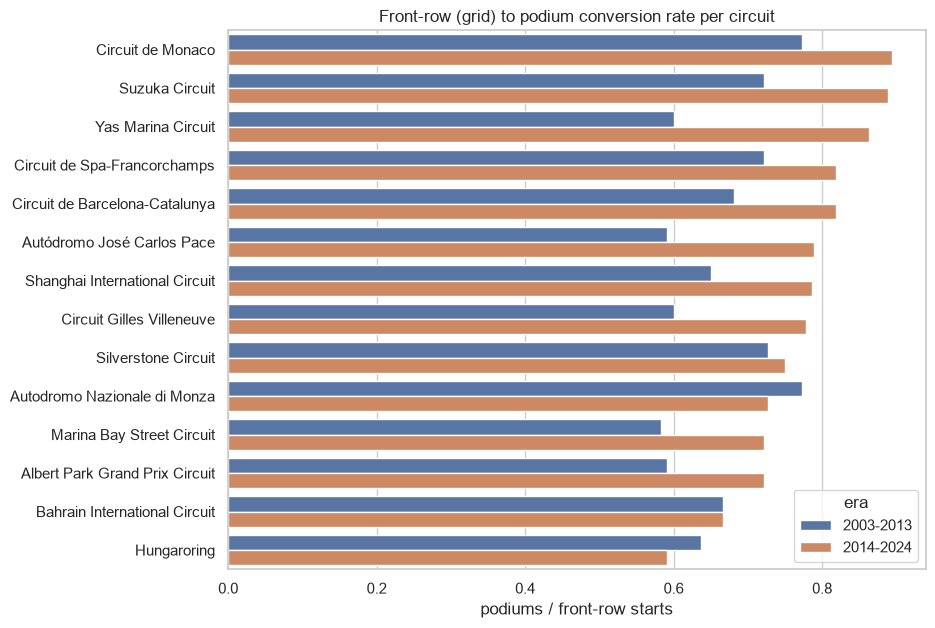

In [44]:
both = by_grid_ok[by_grid_ok['circuit'].isin(rate_grid.index)]

plt.figure(figsize=(9, 7))
sns.barplot(data=both, y='circuit', x='rate', hue='era', order=rate_grid.index)
plt.title('Front-row (grid) to podium conversion rate per circuit')
plt.xlabel('podiums / front-row starts')
plt.ylabel('')
plt.show()

The same data as ranks: one line per circuit, from its rank in 2003–2013 to its rank in 2014–2024. Crossing lines mean the ranking changed. Circuits with exactly the same rate get neighbouring ranks.

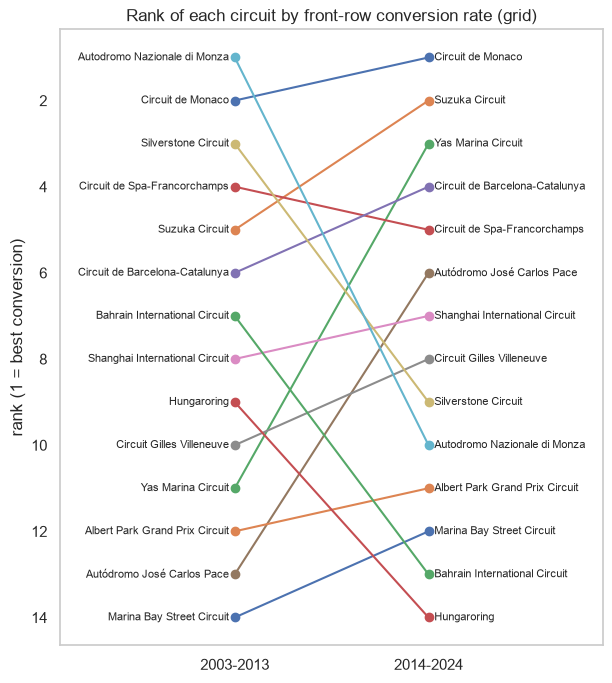

In [45]:
plt.figure(figsize=(7, 8))
for circuit, row in rate_grid.iterrows():
    plt.plot([0, 1], [row['rank_before'], row['rank_after']], marker='o')
    plt.text(-0.03, row['rank_before'], circuit, ha='right', va='center', fontsize=8)
    plt.text(1.03, row['rank_after'], circuit, ha='left', va='center', fontsize=8)
plt.xticks([0, 1], ['2003-2013', '2014-2024'])
plt.xlim(-0.9, 1.9)
plt.gca().invert_yaxis()
plt.ylabel('rank (1 = best conversion)')
plt.title('Rank of each circuit by front-row conversion rate (grid)')
plt.grid(False)
plt.show()

### 6.5 The same with the qualifying definition

Now "front row" means qualifying position 1 or 2, even if a penalty moved the driver back on the grid.

In [46]:
by_quali = q1[q1['front_quali']].groupby(['circuit', 'era']).agg(races=('raceId', 'nunique'), starts=('podium', 'size'), podiums=('podium', 'sum')).reset_index()
by_quali['rate'] = by_quali['podiums'] / by_quali['starts']
by_quali_ok = by_quali[by_quali['races'] >= MIN_RACES]
rate_quali = by_quali_ok.pivot(index='circuit', columns='era', values='rate').dropna()
rate_quali.sort_values('2014-2024', ascending=False).round(3)

era,2003-2013,2014-2024
circuit,,
Circuit de Monaco,0.682,0.895
Suzuka Circuit,0.722,0.889
Circuit de Spa-Francorchamps,0.722,0.818
Yas Marina Circuit,0.600,0.818
Circuit de Barcelona-Catalunya,0.636,0.818
Shanghai International Circuit,0.700,0.786
Silverstone Circuit,0.773,0.750
Autodromo Nazionale di Monza,0.727,0.727
Circuit Gilles Villeneuve,0.600,0.722


In [47]:
# grid definition next to qualifying definition, same circuits
compare = rate_grid[['2003-2013', '2014-2024']].join(rate_quali, lsuffix=' grid', rsuffix=' quali')
compare['diff 2003-2013'] = compare['2003-2013 quali'] - compare['2003-2013 grid']
compare['diff 2014-2024'] = compare['2014-2024 quali'] - compare['2014-2024 grid']
# how similar are the two definitions? rank correlation per era
print('2003-2013:', round(compare['2003-2013 grid'].corr(compare['2003-2013 quali'], method='spearman'), 2),
      '| 2014-2024:', round(compare['2014-2024 grid'].corr(compare['2014-2024 quali'], method='spearman'), 2))
compare.round(3)

2003-2013: 0.89 | 2014-2024: 0.88


era,2003-2013 grid,2014-2024 grid,2003-2013 quali,2014-2024 quali,diff 2003-2013,diff 2014-2024
circuit,,,,,,
Circuit de Monaco,0.773,0.895,0.682,0.895,-0.091,0.000
Suzuka Circuit,0.722,0.889,0.722,0.889,0.000,0.000
Yas Marina Circuit,0.600,0.864,0.600,0.818,0.000,-0.045
Circuit de Spa-Francorchamps,0.722,0.818,0.722,0.818,0.000,0.000
Circuit de Barcelona-Catalunya,0.682,0.818,0.636,0.818,-0.045,0.000
Autódromo José Carlos Pace,0.591,0.789,0.591,0.684,0.000,-0.105
Shanghai International Circuit,0.650,0.786,0.700,0.786,0.050,0.000
Circuit Gilles Villeneuve,0.600,0.778,0.600,0.722,0.000,-0.056
Silverstone Circuit,0.727,0.750,0.773,0.750,0.045,0.000


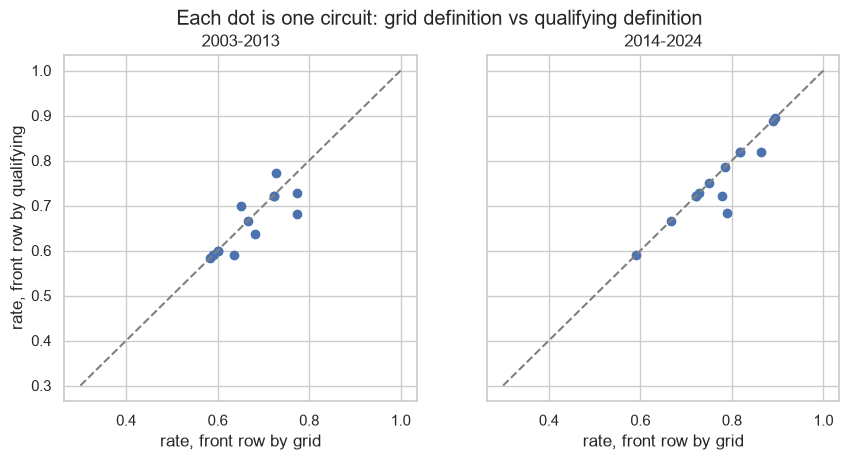

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, era in zip(axes, ['2003-2013', '2014-2024']):
    ax.scatter(compare[era + ' grid'], compare[era + ' quali'])
    ax.plot([0.3, 1], [0.3, 1], color='grey', linestyle='--')
    ax.set_title(era)
    ax.set_xlabel('rate, front row by grid')
axes[0].set_ylabel('rate, front row by qualifying')
plt.suptitle('Each dot is one circuit: grid definition vs qualifying definition')
plt.show()

### 6.6 Justification and answer

**Grain.** One row is one driver who started one race from the front row. The base table is unique on (`raceId`, `driverId`) and its joins did not change the row count, so no front-row start is counted twice. A circuit gets about 2 rows per race.

**Missingness.**
- Qualifying data is missing before 1994 and mostly missing in 1996–2002, so we use 2003–2024 only.
- Inside 2003–2024, 21 starters have no qualifying row. They stay in the table (left join) and simply cannot be "front row by qualifying".
- Drivers who did not start were removed in cleaning. Because of that, 1 race has no front-row starter and a few have one.
- Circuits with fewer than 5 races in an era are not ranked in that era. The ranking comparison uses the 14 circuits that have at least 5 races in both eras.

**Pre-race cutoff.** Both front-row flags are known before the race: qualifying position after the session, grid when the starting grid is published. The podium is the outcome. So this is a description of past races; if a circuit's rate is used as a feature, it must be computed from earlier races only (section 9.8).

**Answer.**

**Overall.** A front-row start became a podium in **68.3%** of cases in 2003–2013 (272 of 398) and in **76.2%** in 2014–2024 (345 of 453). So in the hybrid era the front row is worth more almost everywhere.

**Which circuits convert most often (front row by grid, at least 5 races in the era).**

| 2003–2013 | rate | 2014–2024 | rate |
|---|---|---|---|
| Magny-Cours | 91.7% (11/12) | Monaco | 89.5% (17/19) |
| Istanbul Park | 78.6% (11/14) | Suzuka | 88.9% (16/18) |
| Monza | 77.3% (17/22) | Yas Marina | 86.4% (19/22) |
| Monaco | 77.3% (17/22) | Barcelona-Catalunya | 81.8% (18/22) |
| Silverstone | 72.7% (16/22) | Spa-Francorchamps | 81.8% (18/22) |

**Does the ranking change after 2014?** Yes, quite a lot. For the 14 circuits with at least 5 races in both eras, the rank correlation between the two eras is only 0.36 (1 would mean the same order).
- Monaco stays at the top (77.3% → 89.5%) and Spa and Suzuka stay near the top.
- Big climbers: Yas Marina (60.0% → 86.4%) and Interlagos (59.1% → 78.9%).
- Big fallers: Monza (77.3% → 72.7%, from the top to 10th of 14), Silverstone (72.7% → 75.0%, 3rd to 9th, because the others rose more) and the Hungaroring (63.6% → 59.1%, now last).

**Qualifying position vs grid.** The two differ on 27.5% of all starts from 2003, but the front row is more stable: of 851 top-2 qualifiers, 815 also started on the front row and 36 (4.2%) did not, mostly because of a grid penalty. With the qualifying definition the overall rates are a little lower (67.6% and 74.2%), because a top-2 qualifier who is moved back has a harder race. The circuit ranking is nearly the same with both definitions (rank correlation 0.89 and 0.88). The largest gaps are Monaco in 2003–2013 (77.3% by grid, 68.2% by qualifying) and Interlagos in 2014–2024 (78.9% by grid, 68.4% by qualifying).

**How sure are we?** Not very, for single circuits. Each rate is built on only 10 to 22 front-row starts, so one podium more or less moves it by 5 to 10 points. The overall rise from 68% to 76% is solid; the exact order of neighbouring circuits is not.

---
## 7. Q2 – Do drivers podium more often at home, after controlling for starting position?

### 7.1 Plan and the nationality → country mapping

- **Unit (grain):** one driver starting one race.
- **Home race:** the country of the circuit is the country of the driver's nationality.
- **Joins (multi-hop):** `results → races → circuits` gives the circuit country (in the base table), and `results → drivers` gives the nationality.
- **Control for starting position:** compare home and away drivers inside the same grid group, then combine the groups into one number.

The driver has a demonym (`British`), the circuit has a country name (`UK`). First, `circuits.country` has both `USA` and `United States` for the same country, so we make them one value.

In [49]:
print(merged[merged['country'].isin(['USA', 'United States'])].groupby('country')['circuit'].unique())

merged['country'] = merged['country'].replace('United States', 'USA')
merged[merged['country'].isin(['USA', 'United States'])]['country'].value_counts()

country
USA              [Circuit of the Americas, Long Beach, Las Vega...
United States                     [Las Vegas Strip Street Circuit]
Name: circuit, dtype: object


country
USA    1512
Name: count, dtype: int64

Second, we need a mapping from nationality to country. It is a plain dictionary so every choice is visible. Notes on the unclear ones:

- `Argentine` and `Argentinian` are the same nationality written two ways → `Argentina`.
- `American-Italian` and `Argentine-Italian` (one driver each) → the first nationality.
- `East German` → `Germany` (the German Grand Prix was in West Germany, but it is the closest home race).
- `Monegasque` → `Monaco`.
- `Rhodesian`, `Liechtensteiner` and a few others are mapped to their country, but no race was ever held there, so these drivers have no home race.

In [50]:
nat_to_country = {
    'British': 'UK', 'American': 'USA', 'Italian': 'Italy', 'French': 'France', 'German': 'Germany',
    'Brazilian': 'Brazil', 'Argentine': 'Argentina', 'Argentinian': 'Argentina', 'Swiss': 'Switzerland',
    'Belgian': 'Belgium', 'South African': 'South Africa', 'Japanese': 'Japan', 'Australian': 'Australia',
    'Dutch': 'Netherlands', 'Spanish': 'Spain', 'Austrian': 'Austria', 'Canadian': 'Canada',
    'Swedish': 'Sweden', 'New Zealander': 'New Zealand', 'Finnish': 'Finland', 'Mexican': 'Mexico',
    'Irish': 'Ireland', 'Danish': 'Denmark', 'Portuguese': 'Portugal', 'Monegasque': 'Monaco',
    'Rhodesian': 'Rhodesia', 'Uruguayan': 'Uruguay', 'Russian': 'Russia', 'Colombian': 'Colombia',
    'Venezuelan': 'Venezuela', 'East German': 'Germany', 'Indian': 'India', 'Thai': 'Thailand',
    'Polish': 'Poland', 'Hungarian': 'Hungary', 'Czech': 'Czech Republic', 'Malaysian': 'Malaysia',
    'Chilean': 'Chile', 'Liechtensteiner': 'Liechtenstein', 'American-Italian': 'USA',
    'Argentine-Italian': 'Argentina', 'Indonesian': 'Indonesia', 'Chinese': 'China',
}
drivers['home_country'] = drivers['nationality'].map(nat_to_country)
drivers['home_country'].isna().sum()

np.int64(0)

Every nationality got a country. Now we check which of these countries never held a race in our data. Drivers from there can never be "at home".

In [51]:
race_countries = merged['country'].unique()
no_home = drivers[~drivers['home_country'].isin(race_countries)]
no_home.groupby(['nationality', 'home_country'])['driverId'].count()

nationality      home_country  
Chilean          Chile              1
Colombian        Colombia           3
Czech            Czech Republic     1
Danish           Denmark            5
Finnish          Finland            9
Indonesian       Indonesia          1
Irish            Ireland            5
Liechtensteiner  Liechtenstein      1
New Zealander    New Zealand       10
Polish           Poland             1
Rhodesian        Rhodesia           4
Thai             Thailand           2
Uruguayan        Uruguay            4
Venezuelan       Venezuela          3
Name: driverId, dtype: int64

### 7.2 Build the table: home flag and two filters

Join the nationality onto the base table and mark the home races. The Indianapolis 500 and the drivers who never started are already gone (section 3).

In [52]:
before = len(merged)
q2 = merged.merge(drivers[['driverId', 'nationality', 'home_country']], on='driverId')
q2['home'] = (q2['home_country'] == q2['country']).astype(int)
before, len(q2), q2['home'].sum()

(24571, 24571, np.int64(1928))

**Filter 1: pit-lane starts.** The question controls for starting position, but a pit-lane start had no grid slot (its grid was set to last place + 1 only for the model). We drop them with the flag from section 3.6.

**Filter 2: drivers whose country never held a race.** They are always "away". If we keep them, the away group contains a kind of driver that the home group cannot contain.

In [53]:
print(q2['pit_lane_start'].sum(), 'pit-lane starts')
q2 = q2[q2['pit_lane_start'] == 0]

has_home = q2['home_country'].isin(race_countries)
print((~has_home).sum(), 'starts by', q2[~has_home]['driverId'].nunique(), 'drivers whose country never held a race')
q2 = q2[has_home]

q2['home'].value_counts()

72 pit-lane starts
2324 starts by 43 drivers whose country never held a race


home
0    20248
1     1927
Name: count, dtype: int64

### 7.3 The raw comparison (no control yet)

In [54]:
raw = q2.groupby('home').agg(starts=('podium', 'size'), podiums=('podium', 'sum'), podium_rate=('podium', 'mean'), mean_grid=('grid', 'mean'), median_grid=('grid', 'median'))
raw

,starts,podiums,podium_rate,mean_grid,median_grid
home,,,,,
0,20248,2766,0.136606,11.783139,12.0
1,1927,230,0.119357,12.686559,13.0


Without any control, home drivers reach the podium a little *less* often. But `mean_grid` shows they also start about one place further back on average. So the raw gap mixes "racing at home" with "starting position". Next we take the grid out.

### 7.4 Control: compare inside grid groups

First we look at how strongly the podium depends on the grid, to choose sensible groups.

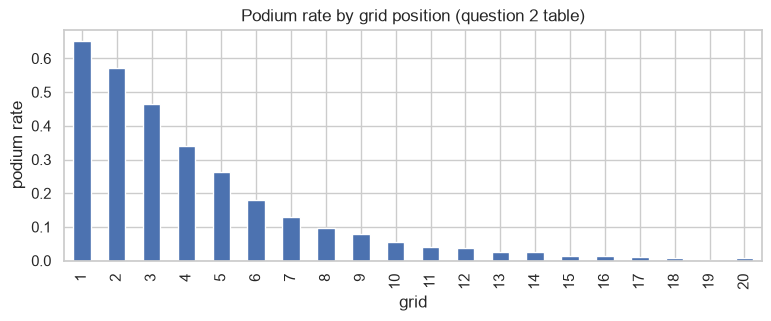

In [55]:
q2[q2['grid'] <= 20].groupby('grid')['podium'].mean().plot(kind='bar', figsize=(9, 3))
plt.title('Podium rate by grid position (question 2 table)')
plt.ylabel('podium rate')
plt.show()

The podium rate falls fast over the first rows and is close to zero after 10th. So the groups are narrow at the front and wide at the back: **1–3, 4–6, 7–10, 11+**.

In [56]:
q2['grid_bin'] = pd.cut(q2['grid'], bins=[0, 3, 6, 10, 40], labels=['1-3', '4-6', '7-10', '11+'])
by_bin = q2.groupby(['grid_bin', 'home'], observed=True).agg(starts=('podium', 'size'), podiums=('podium', 'sum'), rate=('podium', 'mean')).reset_index()

wide = by_bin.pivot(index='grid_bin', columns='home', values=['starts', 'rate'])
wide.columns = ['away_starts', 'home_starts', 'away_rate', 'home_rate']
wide['diff'] = wide['home_rate'] - wide['away_rate']
wide

,away_starts,home_starts,away_rate,home_rate,diff
grid_bin,,,,,
1-3,2747.0,228.0,0.563524,0.574561,0.011038
4-6,2701.0,224.0,0.260644,0.272321,0.011677
7-10,3669.0,335.0,0.090760,0.074627,-0.016134
11+,11131.0,1140.0,0.016261,0.011404,-0.004857


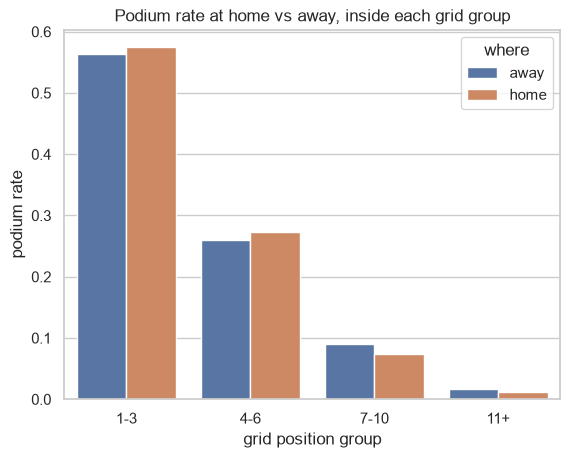

In [57]:
plot_bin = by_bin.copy()
plot_bin['where'] = plot_bin['home'].map({0: 'away', 1: 'home'})

sns.barplot(data=plot_bin, x='grid_bin', y='rate', hue='where')
plt.title('Podium rate at home vs away, inside each grid group')
plt.xlabel('grid position group')
plt.ylabel('podium rate')
plt.show()

### 7.5 One controlled number, and a logistic regression

**Weighted average of the differences.** We take the home-minus-away difference of each grid group and average them, weighted by the number of home starts in the group: "for the grid positions that home drivers really had, how much higher is their podium rate than away drivers from the same positions?"

In [58]:
controlled_diff = (wide['diff'] * wide['home_starts']).sum() / wide['home_starts'].sum()
raw_diff = raw.loc[1, 'podium_rate'] - raw.loc[0, 'podium_rate']
raw_diff, controlled_diff

(np.float64(-0.01724957183749734), np.float64(-0.0030149969096303266))

**Method 2: a simple logistic regression.** `podium ~ grid group + home`. The `home` coefficient says how the odds of a podium change at home for drivers in the same grid group. It also gives a confidence interval, which the weighted average does not.

In [59]:
model = smf.logit('podium ~ C(grid_bin) + home', data=q2).fit()
model.summary().tables[1]

Optimization terminated successfully.
         Current function value: 0.267015
         Iterations 8


,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,0.2620,0.038,6.970,0.000,0.188,0.336
C(grid_bin)[T.4-6],-1.2969,0.056,-23.154,0.000,-1.407,-1.187
C(grid_bin)[T.7-10],-2.5795,0.067,-38.735,0.000,-2.710,-2.449
C(grid_bin)[T.11+],-4.3895,0.081,-54.007,0.000,-4.549,-4.230
home,-0.0397,0.087,-0.454,0.650,-0.211,0.131


In [60]:
# odds ratio of home, with its 95% interval and p-value
np.exp(model.params['home']), np.exp(model.conf_int().loc['home']).tolist(), model.pvalues['home']

(np.float64(0.9611033517474779),
 [0.8099389176418867, 1.1404806370208986],
 np.float64(0.649541145272778))

### 7.6 Justification and answer

**Grain.** One row is one driver starting one race, unique on (`raceId`, `driverId`). The join to `drivers` did not change the row count. The duplicate rule of section 3.4 matters here, because the shared drives of the 1950s are in this table: each driver counts once per race, with the best result.

**Missingness.**
- Drivers who never started and the Indianapolis 500 were removed in cleaning. 72 pit-lane starts are dropped because they had no grid slot to compare.
- No nationality is missing, and every nationality has a country in the mapping. 43 drivers (2,324 starts) come from a country that never held a race; they are left out because they can never be "at home".
- "Home" follows `drivers.nationality`, one value per driver. Dual nationals get the first one, and `East German` drivers are matched to Germany.

**Pre-race cutoff.** `home`, the nationality, the circuit country and `grid` are all known before the race. The podium is the outcome.

**What "controlling" means here.** We compare home and away drivers inside the same grid group. This removes the starting position, but not the car or the driver's skill. So the result is an association, not a cause.

**Answer.**

**No. After controlling for starting position there is no home advantage in this data.**

The table has 22,175 race starts from 1950 to 2024: 1,927 at home and 20,248 away.

- **Raw:** home drivers reach the podium *less* often, 11.9% (230 of 1,927) against 13.7% (2,766 of 20,248). But they also start further back (mean grid 12.7 against 11.8), so home drivers do not qualify better on average.
- **Inside grid groups** (home vs away):

| grid | home | away | difference |
|---|---|---|---|
| 1–3 | 57.5% (131/228) | 56.4% (1,548/2,747) | +1.1 points |
| 4–6 | 27.2% (61/224) | 26.1% (704/2,701) | +1.2 points |
| 7–10 | 7.5% (25/335) | 9.1% (333/3,669) | −1.6 points |
| 11+ | 1.1% (13/1,140) | 1.6% (181/11,131) | −0.5 points |

- **One controlled number:** the weighted average of these differences is **−0.3 percentage points**. The raw gap of −1.7 points almost disappears, so most of it came from the starting position.
- **Logistic regression** (`podium ~ grid group + home`): the odds ratio for home is **0.96**, with a 95% interval from 0.81 to 1.14 and p = 0.65. The interval contains 1, so the data does not show an effect in either direction.

A driver who starts from a similar grid position is about as likely to reach the podium at home as elsewhere. This is a comparison of groups, not proof that racing at home has no effect on a single driver: we did not control for the car or the driver.

---
## 8. Q3 – Which constructors have the highest mechanical-retirement rate in 2014–2021 vs. 2022–2024?

### 8.1 Plan

- **Unit (grain):** one car starting one race.
- **Mechanical-retirement rate of a constructor** = mechanical retirements / race starts, in each period.
- **Joins (multi-hop):** `results → races` gives the year and so the period, `results → status` gives the reason the race ended, `results → constructors` gives the team name (all in the base table).
- The assignment's definition: *a race start that ended early because a component of the car failed; not a crash, not the driver, not a regulation decision.* The base table only has drivers who started, so we need a class for every status.

In [61]:
q3 = merged[merged['year'] >= 2014].copy()
q3['period'] = np.where(q3['year'] <= 2021, '2014-2021', '2022-2024')
q3.groupby('period').agg(races=('raceId', 'nunique'), starts=('raceId', 'size'), constructors=('constructor', 'nunique'))

,races,starts,constructors
period,,,
2014-2021,160,3245,19
2022-2024,68,1352,12


### 8.2 Classify every status

`status.csv` has 139 values but only some appear in these years. We list all of them with their counts, so every one can be classified by hand.

In [62]:
status_counts = q3['status'].value_counts()
print(len(status_counts), 'status values')
status_counts.to_frame().T

65 status values


status,Finished,+1 Lap,+2 Laps,Collision,Accident,Engine,Collision damage,Retired,Brakes,Gearbox,...,Drivetrain,Water pump,Fuel leak,Out of fuel,Spark plugs,+5 Laps,Debris,Differential,Excluded,+7 Laps
count,2403,1178,208,150,85,79,59,49,48,40,...,1,1,1,1,1,1,1,1,1,1


The `+1 Lap`, `+2 Laps`, ... values mean the car was still running at the end, some laps behind the winner. Together with `Finished` they are class `finished`. All the others go in a plain dictionary.

Classes:

- `mechanical` – the status names a part or system of the car that failed.
- `accident` – crash, collision, or damage from one.
- `driver` – caused by the driver.
- `regulation` – decided by the stewards.
- `unclear` – the status does not say why the race ended.

In [63]:
status_class = {
    # a part or system of the car
    'Engine': 'mechanical', 'Power Unit': 'mechanical', 'ERS': 'mechanical', 'Turbo': 'mechanical',
    'Battery': 'mechanical', 'Power loss': 'mechanical', 'Spark plugs': 'mechanical', 'Exhaust': 'mechanical',
    'Gearbox': 'mechanical', 'Transmission': 'mechanical', 'Clutch': 'mechanical', 'Driveshaft': 'mechanical',
    'Drivetrain': 'mechanical', 'Differential': 'mechanical', 'Hydraulics': 'mechanical',
    'Electrical': 'mechanical', 'Electronics': 'mechanical', 'Throttle': 'mechanical',
    'Brakes': 'mechanical', 'Brake duct': 'mechanical', 'Suspension': 'mechanical', 'Steering': 'mechanical',
    'Wheel': 'mechanical', 'Wheel nut': 'mechanical', 'Vibrations': 'mechanical',
    'Oil leak': 'mechanical', 'Oil pressure': 'mechanical', 'Water leak': 'mechanical',
    'Water pressure': 'mechanical', 'Water pump': 'mechanical', 'Radiator': 'mechanical',
    'Overheating': 'mechanical', 'Cooling system': 'mechanical',
    'Fuel pressure': 'mechanical', 'Fuel leak': 'mechanical', 'Fuel system': 'mechanical',
    'Fuel pump': 'mechanical', 'Out of fuel': 'mechanical',
    'Front wing': 'mechanical', 'Rear wing': 'mechanical', 'Undertray': 'mechanical', 'Seat': 'mechanical',
    'Mechanical': 'mechanical', 'Technical': 'mechanical',
    # crash or damage
    'Collision': 'accident', 'Accident': 'accident', 'Collision damage': 'accident',
    'Damage': 'accident', 'Debris': 'accident',
    # the driver
    'Spun off': 'driver', 'Illness': 'driver',
    # the stewards
    'Disqualified': 'regulation', 'Excluded': 'regulation',
    # reason not given
    'Retired': 'unclear', 'Withdrew': 'unclear', 'Puncture': 'unclear', 'Tyre': 'unclear',
    'Finished': 'finished',
}
q3['status_class'] = q3['status'].map(status_class)
q3.loc[q3['status'].str.startswith('+'), 'status_class'] = 'finished'
print('statuses without a class:', q3['status_class'].isna().sum())
q3['status_class'].value_counts()

statuses without a class: 0


status_class
finished      3825
mechanical     387
accident       297
unclear         63
driver          13
regulation      12
Name: count, dtype: int64

No status is left without a class. Here is the full list with class and count, so the reader can check each one.

In [64]:
check = q3.groupby(['status_class', 'status']).size().rename('rows').reset_index().sort_values(['status_class', 'rows'], ascending=[True, False])
pd.set_option('display.max_rows', 200)
check

,status_class,status,rows
1,accident,Collision,150
0,accident,Accident,85
2,accident,Collision damage,59
3,accident,Damage,2
4,accident,Debris,1
6,driver,Spun off,11
5,driver,Illness,2
15,finished,Finished,2403
7,finished,+1 Lap,1178
8,finished,+2 Laps,208


**Borderline calls**

- `Power Unit`, `ERS`, `Turbo`, `Battery` are the hybrid-era names for engine parts → mechanical.
- `Wheel` and `Wheel nut` → mechanical. Often a wheel that was not fixed properly at a pit stop. It is a team error, but the car stopped because a part of it was not working, and it is not a crash, the driver, or a regulation decision.
- `Out of fuel` (1 row) → mechanical, for the same reason.
- `Front wing`, `Rear wing`, `Undertray` → mechanical because the status names a car part. Some may really be contact damage; the data has a separate `Collision damage` status for that, so we trust the label.
- `Collision damage`, `Damage`, `Debris` → accident. The part failed because of a crash or an object on track, which the definition excludes.
- `Spun off` → driver. `Illness` → driver.
- `Puncture` and `Tyre` → unclear. A tyre is a part of the car, but tyres mostly fail from debris, contact or wear, and the status does not say which.
- `Retired` and `Withdrew` → unclear. The team stopped the car and the reason is not recorded. We do not count them, and we test in section 8.6 how much this choice matters.

### 8.3 Failures on lap 0, and classified cars that failed

Cars that never started (`W`, and grid 0 with 0 laps) were removed in cleaning, also when the reason was mechanical: that is a failure, but not a *race start that ended early*. What is left with 0 laps and a mechanical status are cars marked retired (`R`): they stopped before finishing lap 1.

In [65]:
q3[(q3['laps'] == 0) & (q3['status_class'] == 'mechanical')][['year', 'race_name', 'constructor', 'grid', 'positionText', 'status']]

,year,race_name,constructor,grid,positionText,status
15232,2015,Australian Grand Prix,Lotus F1,8,R,Power loss
20223,2022,Saudi Arabian Grand Prix,AlphaTauri,19,R,Power Unit
20451,2018,Italian Grand Prix,Toro Rosso,16,R,Brakes
20927,2017,British Grand Prix,Renault,11,R,Hydraulics
21165,2017,Bahrain Grand Prix,McLaren,17,R,Power Unit
21395,2022,Japanese Grand Prix,Williams,16,R,Hydraulics
21587,2023,Italian Grand Prix,AlphaTauri,11,R,Engine
21731,2018,Hungarian Grand Prix,Sauber,17,R,Suspension


We cannot tell a failure on the formation lap from one in the first corners, so we follow the data and keep them as starts. It is only a handful of rows.

Some mechanical statuses belong to a car that is classified with a number. A car is classified if it did 90% of the distance, even if it stopped before the flag. Its race still ended early because of a failure, so we count it.

In [66]:
q3['mech'] = (q3['status_class'] == 'mechanical').astype(int)
q3[q3['mech'] == 1]['positionText'].str.isdigit().value_counts()

positionText
False    347
True      40
Name: count, dtype: int64

In [67]:
q3.groupby('period')['mech'].agg(['size', 'sum', 'mean'])

,size,sum,mean
period,,,
2014-2021,3245,307,0.094607
2022-2024,1352,80,0.059172


### 8.4 Team lineages and the minimum number of starts

First the simple version: group by the constructor name in the data.

In [68]:
by_name = q3.groupby(['period', 'constructor']).agg(starts=('mech', 'size'), mech=('mech', 'sum'), first=('year', 'min'), last=('year', 'max')).reset_index()
by_name['rate'] = by_name['mech'] / by_name['starts']
by_name.sort_values(['period', 'rate'], ascending=[True, False])

,period,constructor,starts,mech,first,last,rate
4,2014-2021,Caterham,33,7,2014,2014,0.212121
8,2014-2021,Lotus F1,75,14,2014,2015,0.186667
17,2014-2021,Toro Rosso,242,39,2014,2019,0.161157
15,2014-2021,Renault,199,29,2016,2020,0.145729
11,2014-2021,McLaren,316,43,2014,2021,0.136076
14,2014-2021,Red Bull,318,34,2014,2021,0.106918
16,2014-2021,Sauber,199,21,2014,2018,0.105528
10,2014-2021,Marussia,31,3,2014,2014,0.096774
7,2014-2021,Haas F1 Team,241,23,2016,2021,0.095436
1,2014-2021,AlphaTauri,77,7,2020,2021,0.090909


Several teams changed their name, and each name is a different `constructorId`. `Toro Rosso`, `AlphaTauri` and `RB F1 Team` are the same team, and so are `Force India`, `Racing Point` and `Aston Martin`. With the names as given, "2014–2021 vs 2022–2024" cannot be read for them.

**Decision: compare by team lineage.** The same factory and mostly the same people build the car before and after a rename. The mapping is a plain dictionary:

- Toro Rosso → AlphaTauri → RB F1 Team
- Force India → Racing Point → Aston Martin
- Lotus F1 → Renault → Alpine F1 Team (the Enstone team; Renault bought Lotus F1 at the end of 2015)
- Sauber → Alfa Romeo → Sauber
- Marussia → Manor Marussia

A lineage keeps the team but not always the engine supplier, so this is "the team", not "the engine".

In [69]:
lineage = {
    'Toro Rosso': 'Toro Rosso / AlphaTauri / RB',
    'AlphaTauri': 'Toro Rosso / AlphaTauri / RB',
    'RB F1 Team': 'Toro Rosso / AlphaTauri / RB',
    'Force India': 'Force India / Racing Point / Aston Martin',
    'Racing Point': 'Force India / Racing Point / Aston Martin',
    'Aston Martin': 'Force India / Racing Point / Aston Martin',
    'Lotus F1': 'Lotus F1 / Renault / Alpine',
    'Renault': 'Lotus F1 / Renault / Alpine',
    'Alpine F1 Team': 'Lotus F1 / Renault / Alpine',
    'Sauber': 'Sauber / Alfa Romeo',
    'Alfa Romeo': 'Sauber / Alfa Romeo',
    'Marussia': 'Marussia / Manor',
    'Manor Marussia': 'Marussia / Manor',
}
q3['team'] = q3['constructor'].replace(lineage)
q3.groupby('team')['constructor'].unique()

team
Caterham                                                                    [Caterham]
Ferrari                                                                      [Ferrari]
Force India / Racing Point / Aston Martin    [Racing Point, Aston Martin, Force India]
Haas F1 Team                                                            [Haas F1 Team]
Lotus F1 / Renault / Alpine                        [Alpine F1 Team, Renault, Lotus F1]
Marussia / Manor                                            [Marussia, Manor Marussia]
McLaren                                                                      [McLaren]
Mercedes                                                                    [Mercedes]
Red Bull                                                                    [Red Bull]
Sauber / Alfa Romeo                                               [Alfa Romeo, Sauber]
Toro Rosso / AlphaTauri / RB                      [AlphaTauri, Toro Rosso, RB F1 Team]
Williams                              

**Minimum: at least 50 starts in the period.** With fewer than 50 starts a single failure moves the rate by more than 2 points.

In [70]:
by_team = q3.groupby(['period', 'team']).agg(starts=('mech', 'size'), mech=('mech', 'sum')).reset_index()
by_team['rate'] = by_team['mech'] / by_team['starts']

MIN_STARTS = 50
by_team_ok = by_team[by_team['starts'] >= MIN_STARTS]
by_team[by_team['starts'] < MIN_STARTS]

,period,team,starts,mech,rate
0,2014-2021,Caterham,33,7,0.212121


### 8.5 Rate per team, both periods

In [71]:
team_wide = by_team_ok.pivot(index='team', columns='period', values='rate')
team_wide['change'] = team_wide['2022-2024'] - team_wide['2014-2021']
team_wide = team_wide.sort_values('2014-2021', ascending=False)
team_wide.round(3)

period,2014-2021,2022-2024,change
team,,,
Lotus F1 / Renault / Alpine,0.148,0.104,-0.044
Toro Rosso / AlphaTauri / RB,0.144,0.066,-0.078
McLaren,0.136,0.037,-0.099
Red Bull,0.107,0.037,-0.070
Haas F1 Team,0.095,0.052,-0.044
Sauber / Alfa Romeo,0.082,0.088,0.007
Williams,0.075,0.060,-0.016
Marussia / Manor,0.065,NaN,NaN
Force India / Racing Point / Aston Martin,0.063,0.052,-0.011


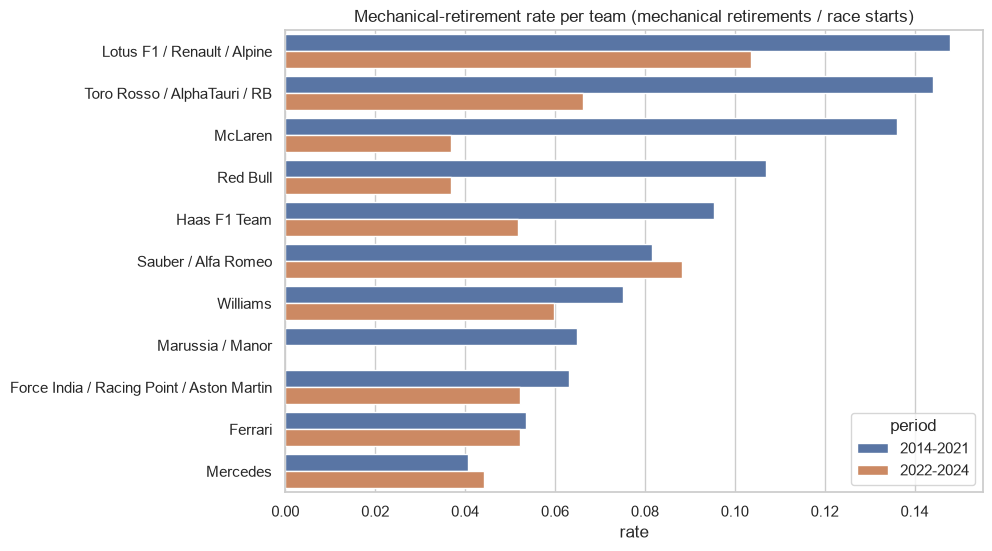

In [72]:
plt.figure(figsize=(9, 6))
sns.barplot(data=by_team_ok, y='team', x='rate', hue='period', order=team_wide.index)
plt.title('Mechanical-retirement rate per team (mechanical retirements / race starts)')
plt.xlabel('rate')
plt.ylabel('')
plt.show()

The bars are sorted by the 2014–2021 rate. `Marussia / Manor` has no second bar because the team stopped after 2016.

### 8.6 Counting the unclear statuses as mechanical

We did not count `Retired`, `Withdrew`, `Puncture` and `Tyre`. Here we count them all as mechanical (the widest possible definition) and check whether the ranking changes.

In [73]:
q3['mech_wide'] = q3['status_class'].isin(['mechanical', 'unclear']).astype(int)
wide_team = q3.groupby(['period', 'team']).agg(starts=('mech', 'size'), rate=('mech', 'mean'), rate_wide=('mech_wide', 'mean')).reset_index()
wide_team = wide_team[wide_team['starts'] >= MIN_STARTS]
wide_team.sort_values(['period', 'rate_wide'], ascending=[True, False]).round(3)

,period,team,starts,rate,rate_wide
4,2014-2021,Lotus F1 / Renault / Alpine,318,0.148,0.167
10,2014-2021,Toro Rosso / AlphaTauri / RB,319,0.144,0.163
6,2014-2021,McLaren,316,0.136,0.155
3,2014-2021,Haas F1 Team,241,0.095,0.124
8,2014-2021,Red Bull,318,0.107,0.116
9,2014-2021,Sauber / Alfa Romeo,319,0.082,0.097
11,2014-2021,Williams,319,0.075,0.094
5,2014-2021,Marussia / Manor,108,0.065,0.083
2,2014-2021,Force India / Racing Point / Aston Martin,317,0.063,0.069
1,2014-2021,Ferrari,317,0.054,0.060


### 8.7 Justification and answer

**Grain.** One row is one car that started one race. The base table is unique on (`raceId`, `driverId`) and its joins did not change the row count. The rate is counted per period and per team, with race starts as the denominator.

**Missingness.**
- `status` is never missing and every status value that appears in 2014–2024 has a class (checked above).
- The real gap is in the meaning: `Retired` and `Withdrew` (and tyre problems) do not say why the car stopped. That is 63 rows, against 387 mechanical ones. We do not count them, and section 8.6 shows the top of the ranking is the same if we do.
- Cars that never started were removed in cleaning, also when the reason was mechanical.
- `Caterham` (one season) is under the minimum of 50 starts and is not ranked. `Marussia / Manor` has no rate for 2022–2024 because the team no longer existed.

**Pre-race cutoff.** `status` is written after the race, so the status of the race being predicted can never be a feature. This section only describes past races. A reliability feature for the model must use earlier races only (section 9.5).

**Answer.**

**Overall.** Cars became more reliable: 9.5% of race starts ended with a mechanical retirement in 2014–2021 (307 of 3,245) and 5.9% in 2022–2024 (80 of 1,352).

**By team lineage (rebrands grouped, at least 50 starts in the period).**

| rank | 2014–2021 | rate | 2022–2024 | rate |
|---|---|---|---|---|
| 1 | Lotus F1 / Renault / Alpine | 14.8% (47/318) | Lotus F1 / Renault / Alpine | 10.4% (14/135) |
| 2 | Toro Rosso / AlphaTauri / RB | 14.4% (46/319) | Sauber / Alfa Romeo | 8.8% (12/136) |
| 3 | McLaren | 13.6% (43/316) | Toro Rosso / AlphaTauri / RB | 6.6% (9/136) |
| 4 | Red Bull | 10.7% (34/318) | Williams | 6.0% (8/134) |
| 5 | Haas | 9.5% (23/241) | Aston Martin lineage, Ferrari, Haas | 5.2% (7 each) |
| last | Mercedes | 4.1% (13/320) | McLaren and Red Bull | 3.7% (5/136 each) |

- The Enstone team (Lotus F1 / Renault / Alpine) has the highest rate in **both** periods.
- The biggest change is at McLaren and Red Bull: 3rd and 4th worst in 2014–2021 (the Honda and Renault power-unit years), the two most reliable in 2022–2024.
- Sauber / Alfa Romeo is the only midfield team that got slightly worse (8.2% → 8.8%) and moved up to 2nd. Mercedes is about the same (4.1% → 4.4%).
- **The unclear statuses do not change this.** Counting `Retired`, `Withdrew` and tyre problems as mechanical raises most rates by 1–3 points, and the Enstone team stays on top in both periods (16.7% and 10.4%), with Sauber / Alfa Romeo right behind in 2022–2024 (10.3%).

**How sure are we?** In 2022–2024 each team has only about 135 starts and 5 to 14 mechanical retirements, so teams one or two retirements apart are not really different. The clear results are the top (Enstone) and the bottom (McLaren, Red Bull) of each list, and the overall drop.

---
## 9. Target and features

Back to the cleaned `df`: we add the target and the features, and save the modeling table.

### 9.1 Target and time order

`podium` is 1 when the driver finished in the top 3. `positionOrder` is filled for every row.

In [74]:
df['podium'] = (df['positionOrder'] <= 3).astype(int)

df['podium'].mean()

np.float64(0.13670587277685076)

About 1 row in 7 is a podium, so the classes are imbalanced. Before any "previous race" feature the rows must be in time order, and `raceId` is not:

In [75]:
races[races['raceId'] <= 2][['raceId', 'year', 'round', 'date']]

,raceId,year,round,date
0,1,2009,1,2009-03-29
1,2,2009,2,2009-04-05


`raceId` 1 is a 2009 race, so we sort by `date`.

In [76]:
df = df.sort_values(['date', 'positionOrder']).reset_index(drop=True)

### 9.2 Grid

Features that use past results only look at **earlier** races. We use **no sprint features**: sprints only exist from 2021, so a sprint column would be empty for every training row (up to 2019), and the sprint format changed almost every year.

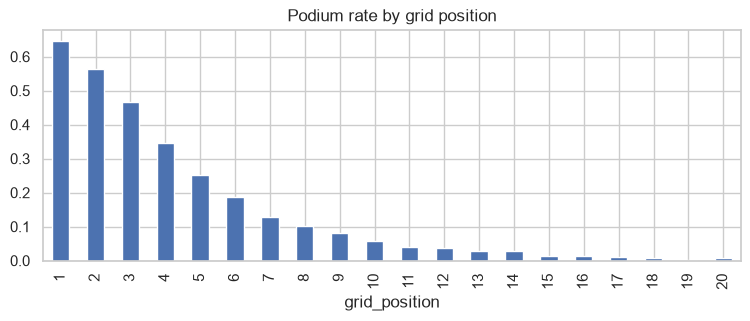

In [77]:
df = df.rename(columns={'grid': 'grid_position'})

df.groupby('grid_position')['podium'].mean().head(20).plot(kind='bar', figsize=(9, 3), title='Podium rate by grid position')
plt.show()

The podium rate falls quickly with grid position, so `grid_position` is a strong feature.

Fields had 20 cars in some years and more than 30 in others, so the same grid number does not always mean the same thing. `grid_position_relative` puts grid on a 0 to 1 scale inside each race. We keep both and compare them later.

In [78]:
df['front_row_start'] = (df['grid_position'] <= 2).astype(int)
df['grid_position_relative'] = df['grid_position'] / df.groupby('raceId')['grid_position'].transform('max')

### 9.3 Qualifying gap and grid penalty

The gap between a driver's best lap and the fastest lap (pole), as a percentage, so a short circuit and a long one can be compared.

In [79]:
qualifying['best_sec'] = qualifying[['q1_sec', 'q2_sec', 'q3_sec']].min(axis=1)
qualifying['pole_sec'] = qualifying.groupby('raceId')['best_sec'].transform('min')
qualifying['qualifying_gap_to_pole_percent'] = (qualifying['best_sec'] / qualifying['pole_sec'] - 1) * 100

quali_small = qualifying[['raceId', 'driverId', 'position', 'qualifying_gap_to_pole_percent']].rename(columns={'position': 'qualifying_position'})
df = df.merge(quali_small, on=['raceId', 'driverId'], how='left')

`has_qualifying_data` is set **per race**: 1 when the race has qualifying data, 0 when it has none, so all drivers of a race are treated the same.

Grid and qualifying position are almost the same number, so we keep only their **difference**: `grid_penalty_places` is positive when a driver starts further back than he qualified. Without a qualifying position it is 0.

In [80]:
df['has_qualifying_data'] = df['raceId'].isin(qualifying['raceId']).astype(int)
print('correlation grid position vs qualifying position:', round(df['grid_position'].corr(df['qualifying_position']), 3))

df['grid_penalty_places'] = (df['grid_position'] - df['qualifying_position']).fillna(0)

correlation grid position vs qualifying position: 0.97


Does the penalty add anything beyond grid? We compare drivers who start 7th to 10th.

In [81]:
mid = df[df['has_qualifying_data'].eq(1) & df['grid_position'].between(7, 10)]
mid.groupby(mid['grid_penalty_places'] >= 3)['podium'].agg(['mean', 'count'])

,mean,count
grid_penalty_places,,
False,0.057351,1918
True,0.217391,46


Drivers moved back 3 or more places reach the podium far more often than others starting from the same place. They are fast cars out of position, and `grid_position` alone cannot see that.

### 9.4 Driver form

Form is how a driver did **in his previous races**. The key step is `shift()`: it moves every value one race down, so a row only sees results from before it.

`Finished` and `+1 Lap`, `+2 Laps`, ... mean the driver reached the flag. Everything else is a retirement (`retired`).

In [82]:
def past_mean(s, n):
    # mean of the previous n rows, not counting the current row
    return s.shift().rolling(n, min_periods=1).mean()

df['retired'] = (~df['status'].str.contains('Finished|Lap')).astype(int)

by_driver = df.groupby('driverId')
df['driver_races_before'] = by_driver.cumcount()
df['driver_podium_rate_last_5_races'] = by_driver['podium'].transform(past_mean, n=5)
df['driver_average_finish_last_5_races'] = by_driver['positionOrder'].transform(past_mean, n=5)
df['driver_retirement_rate_last_10_races'] = by_driver['retired'].transform(past_mean, n=10)
df['driver_career_podium_rate'] = by_driver['podium'].transform(lambda s: s.shift().expanding().mean())
df['driver_podium_rate_at_circuit'] = df.groupby(['driverId', 'circuitId'])['podium'].transform(lambda s: s.shift().expanding().mean())

Check on one driver: the first race is empty, and each value only uses the rows above it.

In [83]:
df[df['driverId'] == 1][['date', 'race_name', 'podium', 'driver_races_before', 'driver_podium_rate_last_5_races', 'driver_career_podium_rate']].head(6)

,date,race_name,podium,driver_races_before,driver_podium_rate_last_5_races,driver_career_podium_rate
17099,2007-03-18,Australian Grand Prix,1,0,NaN,NaN
17120,2007-04-08,Malaysian Grand Prix,1,1,1.0,1.0
17142,2007-04-15,Bahrain Grand Prix,1,2,1.0,1.0
17164,2007-05-13,Spanish Grand Prix,1,3,1.0,1.0
17186,2007-05-27,Monaco Grand Prix,1,4,1.0,1.0
17207,2007-06-10,Canadian Grand Prix,1,5,1.0,1.0


Does recent form say something about the next race? Podium rate in this race, by the driver's podium rate in the previous 5 races. We only use drivers with at least 5 earlier races, so every value is 0, 0.2, ..., 1.

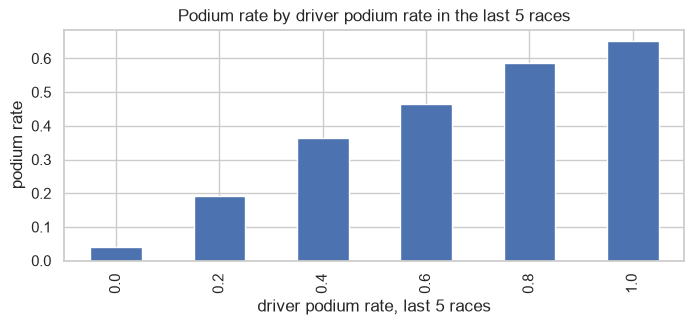

In [84]:
form = df[df['driver_races_before'] >= 5]
form.groupby(form['driver_podium_rate_last_5_races'].round(1))['podium'].mean().plot(kind='bar', figsize=(8, 3), title='Podium rate by driver podium rate in the last 5 races')
plt.xlabel('driver podium rate, last 5 races')
plt.ylabel('podium rate')
plt.show()

The podium rate climbs steadily with recent form: from about 4% for drivers with no podium in their last 5 races to above 60% for drivers with 5 out of 5. Recent form is a strong signal, and it is built from earlier races only.

### 9.5 Constructor form

We do not use the constructor's identity, only how the team performed recently. This also works for a team the model has never seen. A renamed team gets a new `constructorId`, so its history starts empty (a known limitation).

For mechanical retirements we need the statuses where a part of the car failed.

In [85]:
mechanical = [
    'Engine', 'Power Unit', 'ERS', 'Turbo', 'Battery', 'Power loss', 'Spark plugs', 'Exhaust', 'Gearbox',
    'Transmission', 'Clutch', 'Driveshaft', 'Drivetrain', 'Differential', 'Hydraulics', 'Electrical',
    'Electronics', 'Throttle', 'Brakes', 'Brake duct', 'Suspension', 'Steering', 'Wheel', 'Wheel nut',
    'Vibrations', 'Oil leak', 'Oil pressure', 'Water leak', 'Water pressure', 'Water pump', 'Radiator',
    'Overheating', 'Cooling system', 'Fuel pressure', 'Fuel leak', 'Fuel system', 'Fuel pump', 'Out of fuel',
    'Front wing', 'Rear wing', 'Undertray', 'Seat', 'Mechanical', 'Technical',
    # older statuses
    'Driver Seat', 'Broken wing', 'Heat shield fire', 'Wheel rim', 'Track rod', 'Engine fire', 'Engine misfire',
    'Pneumatics', 'Fire', 'Wheel bearing', 'Oil line', 'Launch control', 'Fuel', 'Ignition', 'Chassis',
    'Halfshaft', 'Crankshaft', 'Alternator', 'Safety belt', 'Oil pump', 'Injection', 'Distributor', 'CV joint',
    'Magneto', 'Supercharger', 'Fuel pipe', 'Oil pipe', 'Axle', 'Water pipe',
]
df['mechanical_retirement'] = df['status'].isin(mechanical).astype(int)

# the retirements we did NOT count as mechanical
df[(df['retired'] == 1) & (df['mechanical_retirement'] == 0)]['status'].value_counts().head(12)

status
Accident            981
Collision           850
Spun off            777
Not classified      172
Disqualified        140
Retired              97
Collision damage     60
Tyre                 54
Handling             53
Puncture             41
Physical             30
Withdrew             20
Name: count, dtype: int64

A team has two cars in a race. Shifting row by row would let one car see its teammate's result **from the same race**. So we first make one row per team per race, then look back.

In [86]:
con_race = df.groupby(['constructorId', 'date', 'raceId'])[['podium', 'positionOrder', 'mechanical_retirement']].mean().reset_index()

by_con = con_race.groupby('constructorId')
con_race['constructor_podium_rate_last_5_races'] = by_con['podium'].transform(past_mean, n=5)
con_race['constructor_average_finish_last_5_races'] = by_con['positionOrder'].transform(past_mean, n=5)
con_race['constructor_mechanical_retirement_rate_last_10_races'] = by_con['mechanical_retirement'].transform(past_mean, n=10)

con_cols = ['constructorId', 'raceId', 'constructor_podium_rate_last_5_races', 'constructor_average_finish_last_5_races', 'constructor_mechanical_retirement_rate_last_10_races']
df = df.merge(con_race[con_cols], on=['constructorId', 'raceId'], how='left')

Check: both cars of a team have the same value in a race, and it does not include that race.

In [87]:
df[(df['constructorId'] == 131) & (df['year'] == 2019)][['date', 'race_name', 'driverId', 'podium', 'constructor_podium_rate_last_5_races']].head(4)

,date,race_name,driverId,podium,constructor_podium_rate_last_5_races
22024,2019-03-17,Australian Grand Prix,822,1,0.5
22025,2019-03-17,Australian Grand Prix,1,1,0.5
22044,2019-03-31,Bahrain Grand Prix,1,1,0.5
22045,2019-03-31,Bahrain Grand Prix,822,1,0.5


### 9.6 Standings before the race

The standings tables give the points **after** each race, so the row of the same race would leak the result. We use the row of the **previous round** of the same season.

Points depend on the season's points system (a win was worth 8, 9, 10 or 25), so we divide by the leader's points.

In [88]:
races = races.sort_values(['year', 'round'])
races['prev_raceId'] = races.groupby('year')['raceId'].shift()
df = df.merge(races[['raceId', 'prev_raceId']], on='raceId', how='left')

driver_standings['points_share'] = driver_standings['points'] / driver_standings.groupby('raceId')['points'].transform('max')
drv_prev = driver_standings[['raceId', 'driverId', 'points_share', 'position', 'wins']]
drv_prev.columns = ['prev_raceId', 'driverId', 'driver_points_share_before_race', 'driver_standing_position_before_race', 'driver_season_wins_before_race']
df = df.merge(drv_prev, on=['prev_raceId', 'driverId'], how='left')

constructor_standings['points_share'] = constructor_standings['points'] / constructor_standings.groupby('raceId')['points'].transform('max')
con_prev = constructor_standings[['raceId', 'constructorId', 'points_share', 'position']]
con_prev.columns = ['prev_raceId', 'constructorId', 'constructor_points_share_before_race', 'constructor_standing_position_before_race']
df = df.merge(con_prev, on=['prev_raceId', 'constructorId'], how='left')

How many rows found no standings row?

In [89]:
print('drivers missing:', df['driver_points_share_before_race'].isna().sum(), '| of which round 1:', (df['driver_points_share_before_race'].isna() & df['round'].eq(1)).sum())

df['constructor_points_share_before_race'].isna().groupby(df['year'] // 10 * 10).mean().round(2)

drivers missing: 2889 | of which round 1: 1593


year
1950    0.80
1960    0.13
1970    0.08
1980    0.07
1990    0.09
2000    0.07
2010    0.05
2020    0.05
Name: constructor_points_share_before_race, dtype: float64

- **Round 1**: nobody has points yet.
- **Later rounds**: the table has no row for a driver or team that has not scored yet.
- **Constructors before 1958**: the constructors' championship did not exist, so there is no table.

In the first two cases the true value is 0 points and 0 wins. The **position** stays empty, because there is no honest rank. Before 1958 the constructor columns stay empty.

In [90]:
df['driver_points_share_before_race'] = df['driver_points_share_before_race'].fillna(0)
df['driver_season_wins_before_race'] = df['driver_season_wins_before_race'].fillna(0)

from_1958 = df['year'] >= 1958
df.loc[from_1958, 'constructor_points_share_before_race'] = df.loc[from_1958, 'constructor_points_share_before_race'].fillna(0)

### 9.7 Context

Driver age on race day, home race, and how far into the season the race is. The number of rounds comes from the season calendar, which is known before the season (one exception: the 2020 calendar was built during the season because of COVID, a small limitation).

The home race uses the same nationality → country mapping as Q2 (section 7.1).

In [91]:
circuits['country'] = circuits['country'].replace('United States', 'USA')

df = df.merge(drivers[['driverId', 'dob', 'nationality']], on='driverId', how='left')
df = df.merge(circuits[['circuitId', 'country']], on='circuitId', how='left')

df['driver_age'] = (df['date'] - df['dob']).dt.days / 365.25
df['home_race'] = (df['nationality'].map(nat_to_country) == df['country']).astype(int)
df['season_progress'] = df['round'] / df.groupby('year')['round'].transform('max')

print('nationalities not mapped:', df['nationality'].map(nat_to_country).isna().sum(), '| home race share:', round(df['home_race'].mean(), 3))

nationalities not mapped: 0 | home race share: 0.078


### 9.8 Circuit podium rate per grid group

Circuits behave differently: at some it is very hard to overtake, so a front start is worth more. `circuitId` alone cannot tell a simple model that.

`circuit_podium_rate_for_grid_group` answers: **in earlier races at this circuit, how often did drivers from this part of the grid reach the podium?**

1. Put grid into groups (single positions have too few past cases per circuit).
2. Count podiums and starters per race and grid group. Counting per race first keeps a driver from seeing a rival's result of the same race.

In [92]:
df['grid_group'] = pd.cut(df['grid_position'], [0, 3, 6, 10, 100], labels=['1-3', '4-6', '7-10', '11+']).astype(str)

cg = df.groupby(['date', 'raceId', 'circuitId', 'grid_group'])['podium'].agg(['sum', 'count']).reset_index()
cg.head(4)

,date,raceId,circuitId,grid_group,sum,count
0,1950-05-13,833,9,1-3,2,3
1,1950-05-13,833,9,11+,0,12
2,1950-05-13,833,9,4-6,1,3
3,1950-05-13,833,9,7-10,0,5


3. Add up the **earlier** races only, for this circuit and for all circuits.

In [93]:
def past_sum(s):
    # total of all earlier rows, not counting the current row
    return s.cumsum().shift()

cg['circuit_rate'] = cg.groupby(['circuitId', 'grid_group'])['sum'].transform(past_sum) / cg.groupby(['circuitId', 'grid_group'])['count'].transform(past_sum)
cg['overall_rate'] = cg.groupby('grid_group')['sum'].transform(past_sum) / cg.groupby('grid_group')['count'].transform(past_sum)

4. A circuit with few past races gives a noisy rate. We use the circuit's own rate only when it has at least 5 earlier races. Otherwise (and for new circuits) we use the rate of that grid group over all circuits.

Then a check on some 2019 races: circuits differ, mostly at the front.

In [94]:
race_list = df[['date', 'raceId', 'circuitId']].drop_duplicates()
race_list['circuit_races_before'] = race_list.groupby('circuitId').cumcount()
cg = cg.merge(race_list[['raceId', 'circuit_races_before']], on='raceId')

cg['circuit_podium_rate_for_grid_group'] = cg['circuit_rate'].where(cg['circuit_races_before'] >= 5, cg['overall_rate']).fillna(cg['overall_rate'])
df = df.merge(cg[['raceId', 'grid_group', 'circuit_podium_rate_for_grid_group']], on=['raceId', 'grid_group'], how='left')

df[df['year'] == 2019].groupby(['race_name', 'grid_group'])['circuit_podium_rate_for_grid_group'].first().unstack()[['1-3', '4-6', '7-10', '11+']].round(2).sort_values('1-3').iloc[[0, 1, -2, -1]]

grid_group,1-3,4-6,7-10,11+
race_name,,,,
Austrian Grand Prix,0.44,0.27,0.14,0.02
Italian Grand Prix,0.49,0.32,0.11,0.02
United States Grand Prix,0.76,0.10,0.04,0.03
Russian Grand Prix,0.80,0.07,0.10,0.00


### 9.9 Leakage checks

1. The merges added no rows and the key is unique.
2. No post-race column is in the feature list.

In [95]:
features = [
    'grid_position', 'grid_position_relative', 'front_row_start',
    'grid_penalty_places', 'qualifying_gap_to_pole_percent', 'has_qualifying_data',
    'driver_races_before', 'driver_podium_rate_last_5_races', 'driver_average_finish_last_5_races', 'driver_retirement_rate_last_10_races',
    'driver_career_podium_rate', 'driver_podium_rate_at_circuit',
    'constructor_podium_rate_last_5_races', 'constructor_average_finish_last_5_races', 'constructor_mechanical_retirement_rate_last_10_races',
    'driver_points_share_before_race', 'driver_standing_position_before_race', 'driver_season_wins_before_race',
    'constructor_points_share_before_race', 'constructor_standing_position_before_race',
    'driver_age', 'home_race', 'season_progress', 'circuit_podium_rate_for_grid_group',
]
post_race = ['position', 'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds', 'fastestLap',
             'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId', 'status', 'retired', 'mechanical_retirement']

print('rows:', len(df), '(expected', n_clean, ') | duplicate keys:', df.duplicated(['raceId', 'driverId']).sum())
print('post-race columns in features:', set(features) & set(post_race))

rows: 24571 (expected 24571 ) | duplicate keys: 0
post-race columns in features: set()


3. A form value recomputed by hand: the podium rate of one driver's 5 previous races.

In [96]:
row = df[(df['driver_races_before'] >= 5) & (df['driver_podium_rate_last_5_races'] > 0)].iloc[-1]
past = df[(df['driverId'] == row['driverId']) & (df['date'] < row['date'])].tail(5)

print('by hand:', past['podium'].mean(), '| in table:', row['driver_podium_rate_last_5_races'])

by hand: 0.2 | in table: 0.2


4. A leaked feature would have a correlation with the target close to 1.

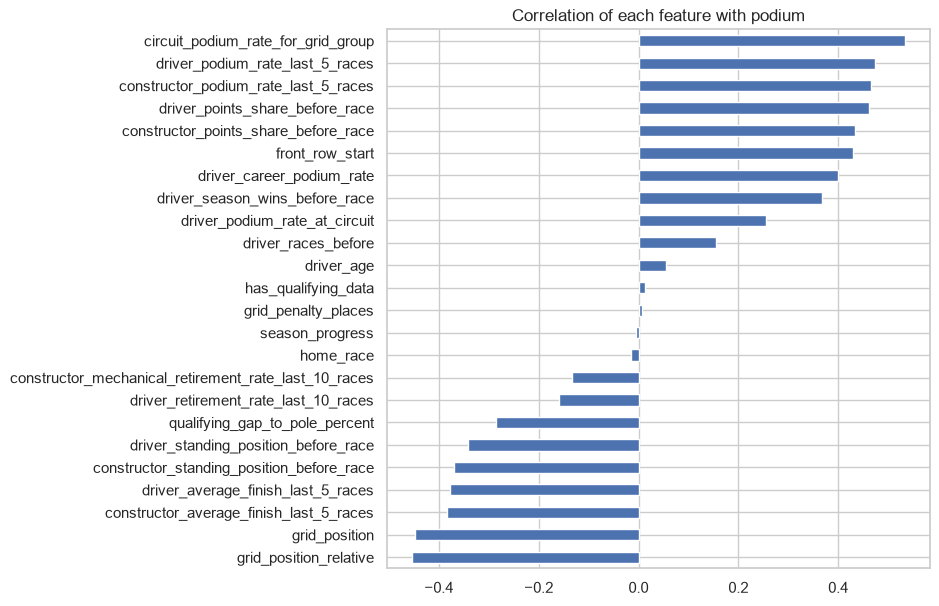

In [97]:
df[features].corrwith(df['podium']).sort_values().plot(kind='barh', figsize=(7, 7), title='Correlation of each feature with podium')
plt.show()

No feature is close to 1 or -1. The strongest are the grid features and the recent form of the driver and the team, as expected. `circuit_podium_rate_for_grid_group` is at the top because it is built from grid.

### 9.10 Split and save

The split is by season: train up to 2019, validation 2020-2021, test from 2022. `year` is only used for the split, it is not a feature.

In [98]:
df['split'] = 'train'
df.loc[df['year'] >= 2020, 'split'] = 'val'
df.loc[df['year'] >= 2022, 'split'] = 'test'

df.groupby('split')['podium'].agg(['count', 'mean'])

,count,mean
split,,
test,1352,0.150888
train,22444,0.135359
val,775,0.150968


Missing values that are left. We do **not** fill them here: any fill value (median, mean, mode) must be learned from the training rows only, so it belongs in the modeling notebook.

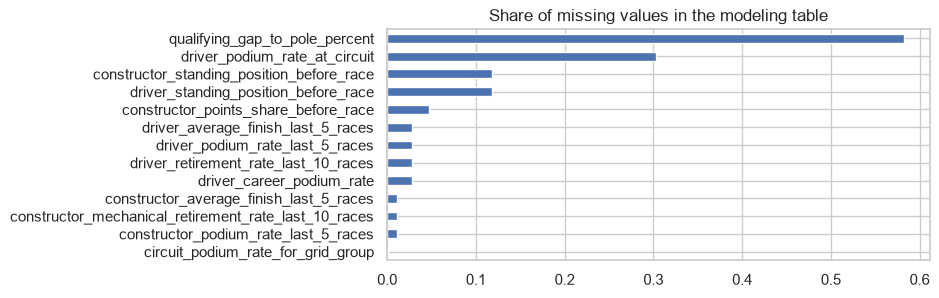

In [99]:
keys = ['raceId', 'driverId', 'constructorId', 'circuitId', 'year', 'round', 'date', 'split']
model_table = df[keys + ['podium'] + features]

missing = model_table.isna().mean()
missing[missing > 0].sort_values().plot(kind='barh', figsize=(7, 3), title='Share of missing values in the modeling table')
plt.show()

Why they are missing:

- `qualifying_gap_to_pole_percent`: no qualifying lap times for most races before 2003.
- `driver_...` form columns: the driver's first race (or first race at this circuit).
- `constructor_...` form columns: the team's first race.
- `driver_standing_position_before_race`, `constructor_standing_position_before_race`: round 1, or no points yet.
- `constructor_points_share_before_race`: before the constructors' championship started in 1958.
- `circuit_podium_rate_for_grid_group`: the very first race, which has no earlier race at all.

In [100]:
os.makedirs(OUT_DIR, exist_ok=True)
model_table.to_csv(OUT_DIR + '/modeling_table.csv', index=False)

model_table.shape

(24571, 33)

### 9.11 The features and why each is known before the race

| Group | Feature | Why it is known before the race |
|---|---|---|
| Grid | `grid_position` | The starting grid is published before the start. |
| Grid | `grid_position_relative` | Grid divided by the largest grid number of the same race. |
| Grid | `front_row_start` | Grid 1 or 2. |
| Qualifying | `grid_penalty_places` | Grid minus qualifying position; both are known before the start. |
| Qualifying | `qualifying_gap_to_pole_percent` | From the qualifying lap times of the same weekend. |
| Qualifying | `has_qualifying_data` | Whether the race has qualifying data at all. (Dropped in section 10.6: it is 1 on every row from 2003.) |
| Driver form | `driver_races_before` | Count of earlier races. |
| Driver form | `driver_podium_rate_last_5_races` | `shift()`: earlier races only. |
| Driver form | `driver_average_finish_last_5_races` | `shift()`: earlier races only. |
| Driver form | `driver_retirement_rate_last_10_races` | `shift()`: earlier races only. |
| Driver form | `driver_career_podium_rate` | `shift()`: earlier races only. |
| Driver form | `driver_podium_rate_at_circuit` | `shift()`: earlier races at this circuit only. |
| Constructor form | `constructor_podium_rate_last_5_races` | One row per team per race, then `shift()`: the teammate's result of the same race is not seen. |
| Constructor form | `constructor_average_finish_last_5_races` | Same. |
| Constructor form | `constructor_mechanical_retirement_rate_last_10_races` | Same. |
| Standings | `driver_points_share_before_race` | Standings after the **previous** round. |
| Standings | `driver_standing_position_before_race` | Same. |
| Standings | `driver_season_wins_before_race` | Same. |
| Standings | `constructor_points_share_before_race` | Same. |
| Standings | `constructor_standing_position_before_race` | Same. |
| Context | `driver_age` | Date of birth and race date. |
| Context | `home_race` | Nationality and circuit country. |
| Context | `season_progress` | Round and the season calendar (2020 is the exception, see 9.7). |
| Context | `circuit_podium_rate_for_grid_group` | Earlier races at the circuit only, plus the grid of this race. |

---
## 10. Pre-processing

### 10.1 Load and split

We read the table saved in section 9.10. The first 8 columns are keys, `podium` is the target, and the other 24 columns are the features, all numbers already, so nothing needs encoding. The grain must still be one row per driver per race.

In [101]:
df = pd.read_csv(OUT_DIR + '/modeling_table.csv')

keys = ['raceId', 'driverId', 'constructorId', 'circuitId', 'year', 'round', 'date', 'split']
features = [c for c in df.columns if c not in keys + ['podium']]

print(df.shape, '|', len(features), 'features | duplicate keys:', df.duplicated(['raceId', 'driverId']).sum())
print(df[features].dtypes.value_counts())
df.head()

(24571, 33) | 24 features | duplicate keys: 0
float64    19
int64       5
Name: count, dtype: int64


,raceId,driverId,constructorId,circuitId,year,round,date,split,podium,grid_position,...,constructor_mechanical_retirement_rate_last_10_races,driver_points_share_before_race,driver_standing_position_before_race,driver_season_wins_before_race,constructor_points_share_before_race,constructor_standing_position_before_race,driver_age,home_race,season_progress,circuit_podium_rate_for_grid_group
0,833,642,51,9,1950,1,1950-05-13,train,1,1,...,NaN,0.0,NaN,0.0,NaN,NaN,43.534565,0,0.142857,NaN
1,833,786,51,9,1950,1,1950-05-13,train,1,2,...,NaN,0.0,NaN,0.0,NaN,NaN,51.923340,0,0.142857,NaN
2,833,686,51,9,1950,1,1950-05-13,train,1,4,...,NaN,0.0,NaN,0.0,NaN,NaN,38.863792,1,0.142857,NaN
3,833,704,154,9,1950,1,1950-05-13,train,0,6,...,NaN,0.0,NaN,0.0,NaN,NaN,45.593429,0,0.142857,NaN
4,833,627,154,9,1950,1,1950-05-13,train,0,9,...,NaN,0.0,NaN,0.0,NaN,NaN,44.517454,0,0.142857,NaN


Section 9.10 saved a `split` column: train up to 2019, validation 2020-2021, test 2022-2024.

We split **by season and not at random** for two reasons:

- At prediction time we only know the past. A random split would train on 2023 races and test on 2021 races.
- The form and standings features of one race are built from the races before it. With a random split, neighbouring races would sit on both sides.

In [102]:
df.groupby('split').agg(first_year=('year', 'min'), last_year=('year', 'max'), rows=('podium', 'size'), podium_rate=('podium', 'mean')).round(3)

,first_year,last_year,rows,podium_rate
split,,,,
test,2022,2024,1352,0.151
train,1950,2019,22444,0.135
val,2020,2021,775,0.151


About 14-15% of the rows are podiums in every split, so the classes are **imbalanced**. A model that always says "no podium" would be right 86% of the time, so accuracy is not a useful metric here (see section 11).

In [103]:
train = df[df['split'] == 'train']
val = df[df['split'] == 'val']
test = df[df['split'] == 'test']

y_train = train['podium']
y_val = val['podium']
y_test = test['podium']

print(train.shape, val.shape, test.shape)

(22444, 33) (775, 33) (1352, 33)


### 10.2 A look at the features (train only)

Section 9 explains how every feature is built and why it is known before the race. Here we look at what they can do for the model, on the **training rows** only, so validation and test stay unseen.

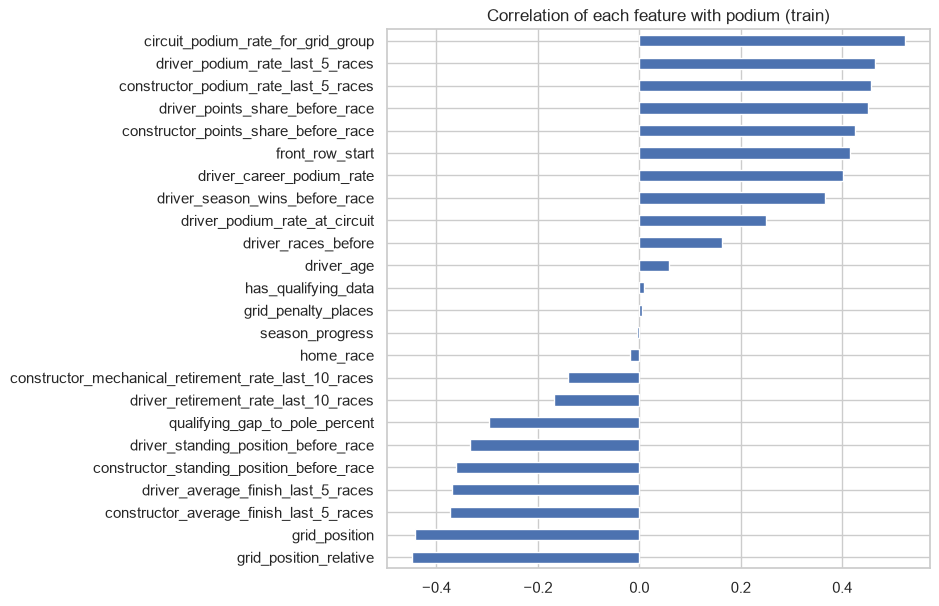

In [104]:
train[features].corrwith(y_train).sort_values().plot(kind='barh', figsize=(7, 7), title='Correlation of each feature with podium (train)')
plt.show()

The grid features, the recent form of driver and team, and the standings are the strongest. `home_race`, `season_progress`, `grid_penalty_places` and `has_qualifying_data` are close to 0 on their own. We keep them anyway (except `has_qualifying_data`, see section 10.6) and let the ablation in section 13 measure them, because a feature can be weak alone and still help next to others.

The start position is the most direct signal, so we look at it on its own.

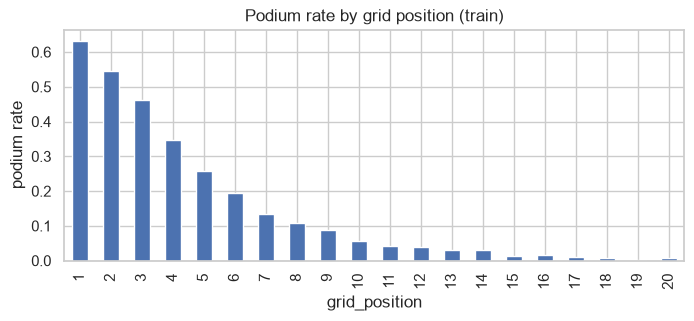

In [105]:
train[train['grid_position'] <= 20].groupby('grid_position')['podium'].mean().plot(kind='bar', figsize=(8, 3), title='Podium rate by grid position (train)')
plt.ylabel('podium rate')
plt.show()

The podium rate falls fast with the grid position and it is not a straight line. This is why we keep `front_row_start` and `circuit_podium_rate_for_grid_group` next to the raw grid position: they help a linear model with the curve.


Two features that say the same thing do not hurt the predictions much, but they make importances harder to read.

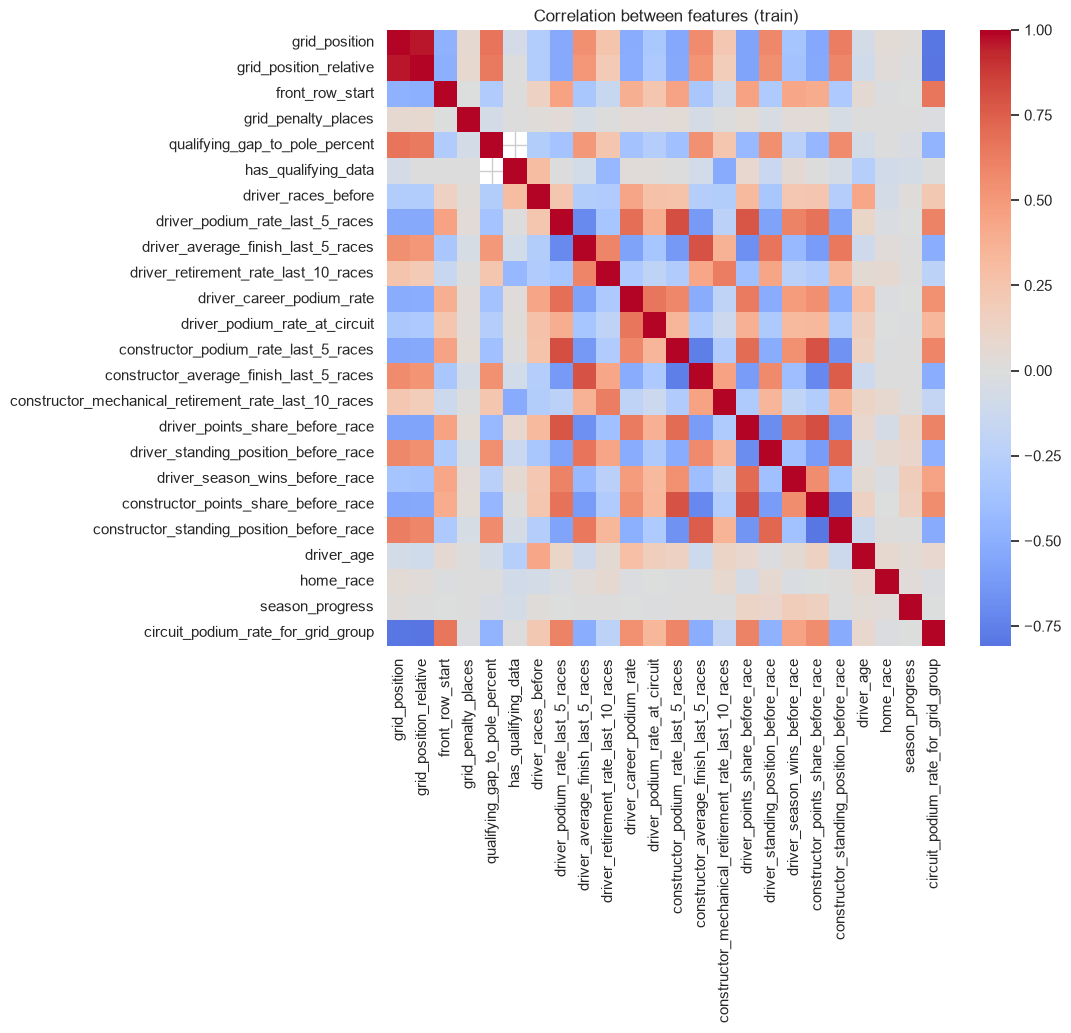

grid_position                    grid_position_relative                  0.96
grid_position_relative           circuit_podium_rate_for_grid_group     -0.81
driver_podium_rate_last_5_races  constructor_podium_rate_last_5_races    0.81
driver_points_share_before_race  constructor_points_share_before_race    0.81
dtype: float64

In [106]:
corr = train[features].corr()

plt.figure(figsize=(9, 8))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation between features (train)')
plt.show()

# keep each pair once (upper triangle), then list the strong ones
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
pairs[pairs.abs() > 0.8].round(2)

Four pairs are above 0.8:

- `grid_position` and `grid_position_relative` (0.96) are almost the same number. Section 13.8 tests whether we need both.
- `circuit_podium_rate_for_grid_group` is built from the grid group, so it follows the grid.
- Driver and constructor form (and driver and constructor points) move together, because a driver's results are also his team's results.

So the groups overlap. We should expect that removing one group costs little, since another group can stand in for it.

### 10.3 Missing values

Section 9.10 left the missing values empty on purpose. We count them per split.

In [107]:
missing = pd.DataFrame({'train': train[features].isna().sum(), 'val': val[features].isna().sum(), 'test': test[features].isna().sum()})
missing[missing['train'] > 0]

,train,val,test
qualifying_gap_to_pole_percent,14284,9,13
driver_podium_rate_last_5_races,667,6,8
driver_average_finish_last_5_races,667,6,8
driver_retirement_rate_last_10_races,667,6,8
driver_career_podium_rate,667,6,8
driver_podium_rate_at_circuit,7058,218,168
constructor_podium_rate_last_5_races,256,4,2
constructor_average_finish_last_5_races,256,4,2
constructor_mechanical_retirement_rate_last_10_races,256,4,2
driver_standing_position_before_race,2778,43,68


13 features have missing values. The big one is `qualifying_gap_to_pole_percent`: empty in 14,284 training rows (no lap times in the old seasons) but almost complete in validation and test.

We fill every missing value with the **median of the training rows**. Median and not mean, because several of these features are skewed. The medians are learned from train only and reused for validation and test, so no information flows back from the later seasons.

In [108]:
medians = train[features].median()

X_train = train[features].fillna(medians)
X_val = val[features].fillna(medians)
X_test = test[features].fillna(medians)

print(X_train.isna().sum().sum(), X_val.isna().sum().sum(), X_test.isna().sum().sum())

0 0 0


No missing values are left. Now the effect on the feature that was filled the most.

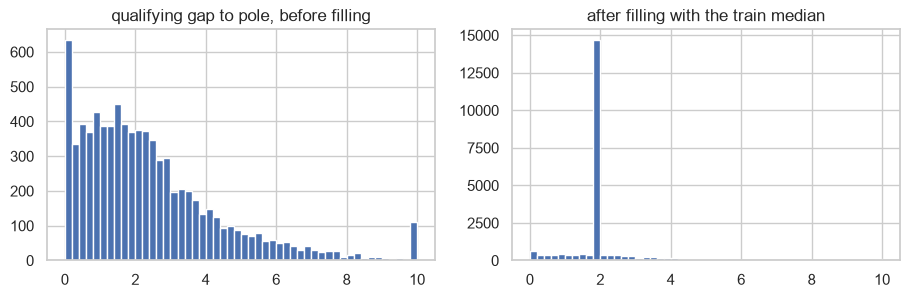

In [109]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
train['qualifying_gap_to_pole_percent'].clip(upper=10).hist(bins=50, ax=ax[0])
ax[0].set_title('qualifying gap to pole, before filling')
X_train['qualifying_gap_to_pole_percent'].clip(upper=10).hist(bins=50, ax=ax[1])
ax[1].set_title('after filling with the train median')
plt.show()

Filling puts 14,284 rows on one value, so the feature now has a tall spike at the median. For those rows it carries no information. Almost all of them are from before 2003, and section 10.5 checks whether we need those old seasons at all. We test adding more "was missing" flags in section 14.3.

### 10.4 Scaling

The features have very different ranges.

In [110]:
X_train.describe().T[['mean', 'std', 'min', 'max']].round(2)

,mean,std,min,max
grid_position,11.91,6.81,1.00,34.0
grid_position_relative,0.52,0.29,0.03,1.0
front_row_start,0.09,0.28,0.00,1.0
grid_penalty_places,-0.00,0.85,-9.00,23.0
qualifying_gap_to_pole_percent,2.16,1.57,0.00,37.8
has_qualifying_data,0.37,0.48,0.00,1.0
driver_races_before,61.45,61.59,0.00,321.0
driver_podium_rate_last_5_races,0.13,0.23,0.00,1.0
driver_average_finish_last_5_races,11.75,4.36,1.00,31.0
driver_retirement_rate_last_10_races,0.42,0.25,0.00,1.0


`driver_races_before` goes up to a few hundred while the rates stay between 0 and 1. Logistic regression (with its penalty) and the neural network both work better when the features are on the same scale, so we standardise: subtract the mean and divide by the standard deviation.

The mean and standard deviation come from the **training rows only**, like the medians.

In [111]:
mean = X_train.mean()
std = X_train.std()

X_train_s = (X_train - mean) / std
X_val_s = (X_val - mean) / std
X_test_s = (X_test - mean) / std

X_train_s.describe().T[['mean', 'std', 'min', 'max']].round(2)

,mean,std,min,max
grid_position,-0.0,1.0,-1.60,3.24
grid_position_relative,-0.0,1.0,-1.71,1.66
front_row_start,-0.0,1.0,-0.31,3.20
grid_penalty_places,0.0,1.0,-10.59,27.07
qualifying_gap_to_pole_percent,-0.0,1.0,-1.37,22.66
has_qualifying_data,-0.0,1.0,-0.77,1.30
driver_races_before,-0.0,1.0,-1.00,4.21
driver_podium_rate_last_5_races,0.0,1.0,-0.57,3.71
driver_average_finish_last_5_races,0.0,1.0,-2.47,4.42
driver_retirement_rate_last_10_races,0.0,1.0,-1.69,2.38


Every feature now has mean 0 and standard deviation 1 on train. The shape of each distribution is the same as before, only the axis changed.

Tree models split on thresholds, so scaling changes nothing for them. They get the filled, unscaled table (`X_train`), which keeps their plots in real units. Logistic regression and the neural network get the scaled table (`X_train_s`). All models use the **same rows, the same features and the same filled values**.

### 10.5 Which seasons to train on?

The training split has every season from 1950 to 2019. F1 in the 1950s was a different sport: other points, shared cars, bigger fields, and before 2003 mostly no qualifying lap times (section 2.8). Old rows give the model more examples, but they may also teach it patterns that no longer hold.

We try three start years: **1950** (all seasons), **1994** (the first season with qualifying data) and **2003** (the first season with complete qualifying data). For each one we train a logistic regression and compare PR-AUC on **validation only**. The test set is not used for this choice.

In [112]:
rows = []
for start in [1950, 1994, 2003]:
    mask = train['year'] >= start
    m = LogisticRegression(max_iter=1000).fit(X_train_s[mask], y_train[mask])
    rows.append([start, mask.sum(), average_precision_score(y_val, m.predict_proba(X_val_s)[:, 1])])

pd.DataFrame(rows, columns=['train from', 'train rows', 'val_pr_auc']).round(4)

,train from,train rows,val_pr_auc
0,1950,22444,0.7459
1,1994,10091,0.7519
2,2003,6782,0.7493


The three start years are within 0.006 of each other (0.746, 0.752 and 0.749). Section 12.4 shows that a difference below about 0.01 is noise, so the three options are **tied**: the seasons before 1994 and before 2003 do not make the model better.

**Decision: train on 2003-2019.** When older seasons add no value, it makes more sense to train on the recent ones:

- They were raced under rules much closer to today's (points system, qualifying format, car reliability), which are the rules the validation and test races follow.
- From 2003 the qualifying data is complete, so `qualifying_gap_to_pole_percent` is a real value on almost every row instead of a filled median. This removes the qualifying-coverage drift from the training data.
- It is the same rule we use for models in section 13.4: when options are tied, we take the simpler one.
- It matches Q1 (section 6), which also uses 2003 onwards for the same reason.

1994 scores 0.003 higher than 2003, but that is far inside the noise, and the 1996-2002 seasons still have patchy qualifying data (section 2.8).

### 10.6 Train on 2003-2019 only

We drop the rows before 2003. The form and career features were built in section 9 from the full history, so a 2003 row still knows what a driver did before 2003. We only stop using the old races as training examples. Validation and test do not change.

In [113]:
df = df[df['year'] >= 2003]
train = df[df['split'] == 'train']
y_train = train['podium']

train.shape

(6782, 33)

From 2003 every race has qualifying data, so `has_qualifying_data` should now be the same on every training row. We check.

In [114]:
train['has_qualifying_data'].value_counts()

has_qualifying_data
1    6782
Name: count, dtype: int64

It is 1 on every row (and on every validation and test row too). A column with one value tells the model nothing, and its standard deviation is 0, so the scaling would divide by 0. We drop it.

In [115]:
features.remove('has_qualifying_data')
len(features)

23

The missing values on the new training rows.

In [116]:
missing = train[features].isna().sum()
missing[missing > 0]

qualifying_gap_to_pole_percent                           122
driver_podium_rate_last_5_races                           75
driver_average_finish_last_5_races                        75
driver_retirement_rate_last_10_races                      75
driver_career_podium_rate                                 75
driver_podium_rate_at_circuit                           1622
constructor_podium_rate_last_5_races                      35
constructor_average_finish_last_5_races                   35
constructor_mechanical_retirement_rate_last_10_races      35
driver_standing_position_before_race                     483
constructor_standing_position_before_race                384
dtype: int64

`qualifying_gap_to_pole_percent` is now missing in only 122 training rows instead of 14,284. The other gaps are a driver's or team's first races, the first race at a circuit, and round 1 of a season.

The medians, means and standard deviations of sections 10.3 and 10.4 were learned on 1950-2019, so we learn them again on the new training rows, with the same lines.

In [117]:
medians = train[features].median()
X_train = train[features].fillna(medians)
X_val = val[features].fillna(medians)
X_test = test[features].fillna(medians)

mean = X_train.mean()
std = X_train.std()
X_train_s = (X_train - mean) / std
X_val_s = (X_val - mean) / std
X_test_s = (X_test - mean) / std

print(X_train_s.shape, X_val_s.shape, X_test_s.shape)

(6782, 23) (775, 23) (1352, 23)


---
## 11. Metrics

### 11.1 The metrics and the primary metric

We report five metrics for every model:

| Metric | What it tells us |
|---|---|
| ROC-AUC | How well the model ranks podium rows above the others, over all thresholds. |
| PR-AUC | The same, but it only looks at precision and recall of the podium class. |
| F1 | Balance of precision and recall at one threshold. |
| Precision | Of the rows we call podium, how many are. |
| Recall | Of the real podiums, how many we find. |

- **Primary metric: PR-AUC.** Only 14% of the rows are podiums. ROC-AUC also rewards the model for the many easy "no podium" rows at the back of the grid, so it looks high for every model. PR-AUC only moves when the podium rows are ranked better.
- **Secondary metric: ROC-AUC**, to compare with other work, and **F1** for the final yes/no decision.

### 11.2 The threshold is picked on validation

F1, precision and recall need a threshold. The default 0.5 is a poor choice with rare positives, so for each model we take the threshold with the **best F1 on the validation set**. The test set is never used for this.

These steps are the same for every model, so they go in three small functions.

In [118]:
results = []      # one row per model and split
thresholds = {}   # the chosen threshold of each model
cols = ['model', 'split', 'roc_auc', 'pr_auc', 'f1', 'precision', 'recall']

def best_threshold(y, p):
    # the threshold with the highest F1
    precision, recall, cuts = precision_recall_curve(y, p)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    return cuts[f1[:-1].argmax()]

def add_scores(name, split, y, p):
    pred = (p >= thresholds[name]).astype(int)
    results.append([name, split, roc_auc_score(y, p), average_precision_score(y, p), f1_score(y, pred), precision_score(y, pred), recall_score(y, pred)])

def evaluate(name, p_train, p_val):
    # pick the threshold on validation, then score train and validation
    thresholds[name] = best_threshold(y_val, p_val)
    add_scores(name, 'train', y_train, p_train)
    add_scores(name, 'val', y_val, p_val)
    return pd.DataFrame(results[-2:], columns=cols).round(3)

---
## 12. Models

### 12.1 Logistic regression (the baseline model)

**How it works:** it multiplies each feature by a weight, adds them up, and squeezes the sum into a probability between 0 and 1. Training finds the weights.

**Limits:** each feature can only push the probability up or down in one direction, and features cannot interact unless we build the interaction ourselves.

It is the simplest reasonable model for a yes/no target, so it is our **baseline**: every other model must beat it to be worth its extra complexity. First with the default settings.

In [119]:
lr = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)

evaluate('Logistic regression', lr.predict_proba(X_train_s)[:, 1], lr.predict_proba(X_val_s)[:, 1])

,model,split,roc_auc,pr_auc,f1,precision,recall
0,Logistic regression,train,0.933,0.695,0.673,0.589,0.784
1,Logistic regression,val,0.932,0.749,0.711,0.662,0.769


The scores are higher on validation than on train (PR-AUC 0.749 against 0.695). This is true for every model below except the forest. Validation has only 775 rows, and the 2020-2021 seasons happened to be easier to predict than the 2003-2019 average (two teams took most of the podiums).

The main setting is `C`, the strength of the penalty on the weights (small `C` = strong penalty). We try four values and compare PR-AUC on validation.

In [120]:
rows = []
for C in [0.01, 0.1, 1, 10]:
    m = LogisticRegression(C=C, max_iter=1000).fit(X_train_s, y_train)
    rows.append([C, average_precision_score(y_train, m.predict_proba(X_train_s)[:, 1]), average_precision_score(y_val, m.predict_proba(X_val_s)[:, 1])])

pd.DataFrame(rows, columns=['C', 'train_pr_auc', 'val_pr_auc']).round(4)

,C,train_pr_auc,val_pr_auc
0,0.01,0.6932,0.7486
1,0.10,0.6952,0.7514
2,1.00,0.6955,0.7494
3,10.00,0.6956,0.7490


Train and validation move together, so it does not overfit.

`C` changes almost nothing: the four values are within 0.003 of each other on validation. That is far too small to mean anything with 117 validation podiums, so we keep the default `C = 1`.

### 12.2 Random forest

**How it works:** it grows many decision trees, each on a random sample of the rows and with a random choice of features at every split, and averages their votes.

**Why try it:** trees handle curves and interactions on their own (for example "front of the grid **and** a strong team").

**Limits:** deep trees memorise the training rows, and a forest cannot predict outside what it has seen.

First with the default settings (300 trees so the result is stable).

In [121]:
rf_default = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train, y_train)

print('train PR-AUC:', round(average_precision_score(y_train, rf_default.predict_proba(X_train)[:, 1]), 3))
print('val PR-AUC:  ', round(average_precision_score(y_val, rf_default.predict_proba(X_val)[:, 1]), 3))

train PR-AUC: 1.0
val PR-AUC:   0.657


The default forest is perfect on train and clearly worse on validation: it **overfits**. The default trees grow until every leaf is pure. We limit the depth and look again.

In [122]:
rows = []
for depth in [3, 5, 10, None]:
    m = RandomForestClassifier(n_estimators=300, max_depth=depth, random_state=42, n_jobs=-1).fit(X_train, y_train)
    rows.append([depth, average_precision_score(y_train, m.predict_proba(X_train)[:, 1]), average_precision_score(y_val, m.predict_proba(X_val)[:, 1])])

pd.DataFrame(rows, columns=['max_depth', 'train_pr_auc', 'val_pr_auc']).round(4)

,max_depth,train_pr_auc,val_pr_auc
0,3.0,0.7156,0.7220
1,5.0,0.7643,0.7237
2,10.0,0.9686,0.6942
3,NaN,1.0000,0.6570


The shallower the trees, the lower the train score and the **higher** the validation score. Depth 3 and depth 5 are the same on validation (0.722 and 0.724) and both are clearly better than the default (0.657). We take `max_depth = 5`.

In [123]:
rf = RandomForestClassifier(n_estimators=300, max_depth=5, random_state=42, n_jobs=-1).fit(X_train, y_train)

evaluate('Random forest', rf.predict_proba(X_train)[:, 1], rf.predict_proba(X_val)[:, 1])

,model,split,roc_auc,pr_auc,f1,precision,recall
0,Random forest,train,0.948,0.764,0.684,0.564,0.870
1,Random forest,val,0.934,0.724,0.713,0.646,0.795


### 12.3 Shallow neural network

**How it works:** each hidden unit is a small logistic regression. A hidden layer has several of them, and the output unit combines them into one probability. With no hidden layer the network would be exactly a logistic regression.

**Limits:** the result changes with the random start, it needs scaled inputs, and it is harder to explain than a list of weights.

We use Keras with two hidden layers of 32 and 16 units:

- `relu` hidden layers and one `sigmoid` output, because the target is yes/no
- **dropout** of 0.2 (during training, 20% of the units are switched off at random in each step), so the network does not memorise the training rows
- `binary_crossentropy` loss with the `adam` optimiser (the standard pair for this)
- **early stopping**: training stops when the validation loss has not improved for 10 epochs, and the best weights are kept
- a fixed seed so Run All gives the same result

The training steps are needed again in section 12.4, so they go in one function.

In [124]:
def train_nn(hidden, dropout, seed):
    keras.utils.set_random_seed(seed)
    nn = keras.Sequential([keras.Input(shape=(len(features),))])
    for units in hidden:
        nn.add(layers.Dense(units, activation='relu'))
        nn.add(layers.Dropout(dropout))
    nn.add(layers.Dense(1, activation='sigmoid'))
    nn.compile(optimizer='adam', loss='binary_crossentropy')
    stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)
    history = nn.fit(X_train_s, y_train, validation_data=(X_val_s, y_val), epochs=100, batch_size=64, verbose=0, callbacks=[stop])
    return nn, history

In [125]:
net, history = train_nn([32, 16], 0.2, 42)
net.summary()

evaluate('Neural network (32-16)', net.predict(X_train_s, verbose=0).ravel(), net.predict(X_val_s, verbose=0).ravel())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,941 (15.40 KB)

 Trainable params: 1,313 (5.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,628 (10.27 KB)

,model,split,roc_auc,pr_auc,f1,precision,recall
0,Neural network (32-16),train,0.941,0.713,0.688,0.668,0.709
1,Neural network (32-16),val,0.927,0.734,0.706,0.703,0.709


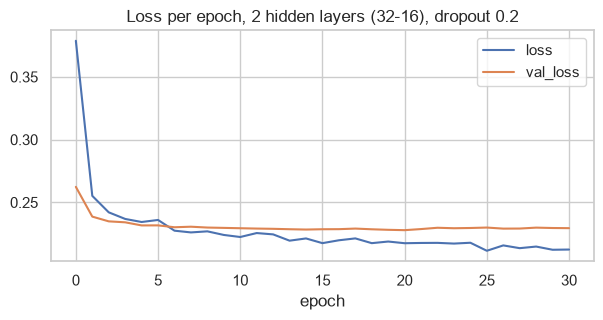

In [126]:
pd.DataFrame(history.history).plot(figsize=(7, 3), title='Loss per epoch, 2 hidden layers (32-16), dropout 0.2')
plt.xlabel('epoch')
plt.show()

The network stops on its own (early stopping). After about 7 epochs the train loss keeps falling while the validation loss stays flat, so the network starts to learn things that only hold for the training rows. Early stopping cuts this off and keeps the weights of the best epoch, and dropout keeps the gap small.

It reaches a validation PR-AUC of 0.734, below the 0.749 of the logistic regression. Section 12.4 checks how much of that gap is noise.

### 12.4 Seed noise

A network starts from random weights. We train the two-layer network again with three other seeds to see how far the validation score moves from the seed alone.

In [127]:
rows = []
for seed in [1, 2, 3]:
    m, h = train_nn([32, 16], 0.2, seed)
    p = m.predict(X_val_s, verbose=0).ravel()
    rows.append([seed, roc_auc_score(y_val, p), average_precision_score(y_val, p)])

pd.DataFrame(rows, columns=['seed', 'val_roc_auc', 'val_pr_auc']).round(4)

,seed,val_roc_auc,val_pr_auc
0,1,0.9260,0.7311
1,2,0.9281,0.7425
2,3,0.9250,0.7308


With the same data and the same network, the validation PR-AUC moves between about 0.731 and 0.743 just from the random start. On another machine the numbers can shift by a similar amount.

This gives us a feel for the noise: **a difference of less than about 0.01 in validation PR-AUC between two models is not a real difference.**

---
## 13. Evaluation

### 13.1 Score every model on the test set, once

Everything so far was chosen with train and validation only. Now we score the final version of each model on the test set (2022-2024), **once**, with the thresholds picked on validation.

In [128]:
p_test = {
    'Logistic regression': lr.predict_proba(X_test_s)[:, 1],
    'Random forest': rf.predict_proba(X_test)[:, 1],
    'Neural network (32-16)': net.predict(X_test_s, verbose=0).ravel(),
}
for name, p in p_test.items():
    add_scores(name, 'test', y_test, p)

table = pd.DataFrame(results, columns=cols)
table['threshold'] = table['model'].map(thresholds)

### 13.2 Validation, test and train

**Validation**

In [129]:
table[table['split'] == 'val'].drop(columns='split').set_index('model').round(3)

,roc_auc,pr_auc,f1,precision,recall,threshold
model,,,,,,
Logistic regression,0.932,0.749,0.711,0.662,0.769,0.268
Random forest,0.934,0.724,0.713,0.646,0.795,0.212
Neural network (32-16),0.927,0.734,0.706,0.703,0.709,0.420


**Test (unseen)**

In [130]:
table[table['split'] == 'test'].drop(columns='split').set_index('model').round(3)

,roc_auc,pr_auc,f1,precision,recall,threshold
model,,,,,,
Logistic regression,0.937,0.725,0.684,0.585,0.824,0.268
Random forest,0.940,0.714,0.689,0.571,0.868,0.212
Neural network (32-16),0.930,0.710,0.671,0.648,0.696,0.420


**Train (to see overfitting)**

In [131]:
table[table['split'] == 'train'].drop(columns='split').set_index('model').round(3)

,roc_auc,pr_auc,f1,precision,recall,threshold
model,,,,,,
Logistic regression,0.933,0.695,0.673,0.589,0.784,0.268
Random forest,0.948,0.764,0.684,0.564,0.870,0.212
Neural network (32-16),0.941,0.713,0.688,0.668,0.709,0.420


### 13.3 Plots

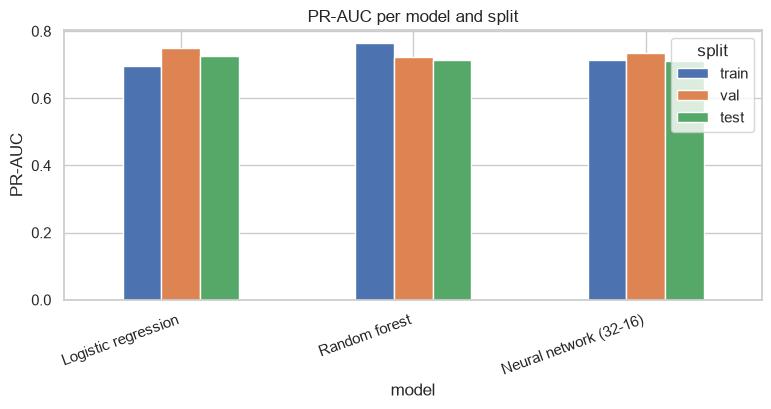

In [132]:
table.pivot(index='model', columns='split', values='pr_auc')[['train', 'val', 'test']].loc[list(p_test)].plot(kind='bar', figsize=(9, 3.5), title='PR-AUC per model and split')
plt.ylabel('PR-AUC')
plt.xticks(rotation=20, ha='right')
plt.show()

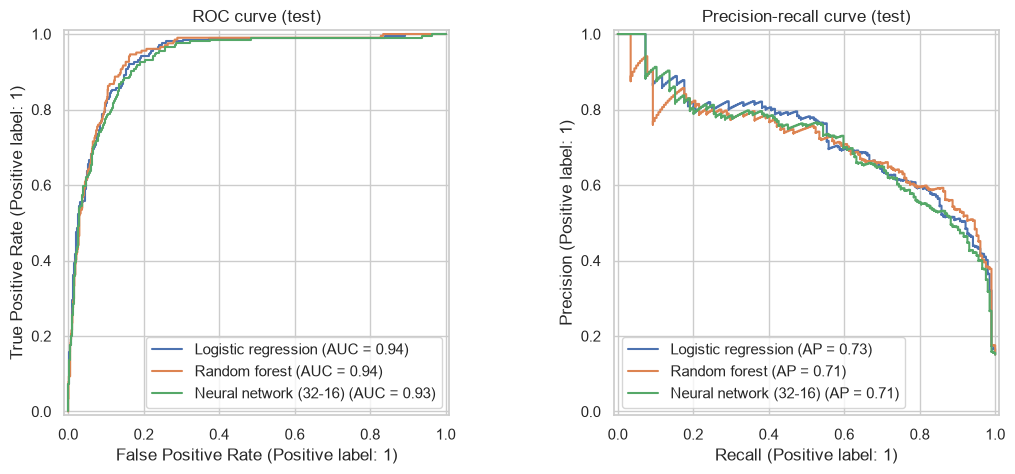

In [133]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, p in p_test.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_test, p, name=name, ax=ax[1])
ax[0].set_title('ROC curve (test)')
ax[1].set_title('Precision-recall curve (test)')
plt.show()

### 13.4 The final model, against the baseline

**What we see**

- **Neither complex model beats the baseline.** Validation PR-AUC: logistic regression 0.749, random forest 0.724, neural network 0.734. Test PR-AUC: 0.725, 0.714 and 0.710. The logistic regression is first on both, but the network's own seeds range from 0.731 to 0.743 (section 12.4), so the gap to the network is about the size of the noise.
- **The forest fits the training rows the closest** (train PR-AUC 0.764) but is the lowest on validation, so a little of its fit does not carry over. The logistic regression and the network show no overfitting: validation and test are at or above train.
- **Thresholds carry over well.** The F1 on test (0.67-0.69) is a bit lower than on validation (0.71), which is expected because the thresholds were tuned on validation.

**Final model: logistic regression, our baseline.** We chose it from the validation column: it has the highest validation PR-AUC, and even where the gap is inside the noise, when models are tied we take the simplest one. Neither the forest nor the network earned its extra complexity. The logistic regression trains in a second, gives the same result on every run, and its weights can be read directly. The test column then confirms the choice (PR-AUC 0.725, ROC-AUC 0.937), but it was not used to make it.

**Why did the complex models not win?** The features already do the hard work: form, standings and the circuit rate are built by hand in section 9, so there is little left for trees or hidden layers to discover. The training data is also small (6,782 rows, about 20 cars per race).

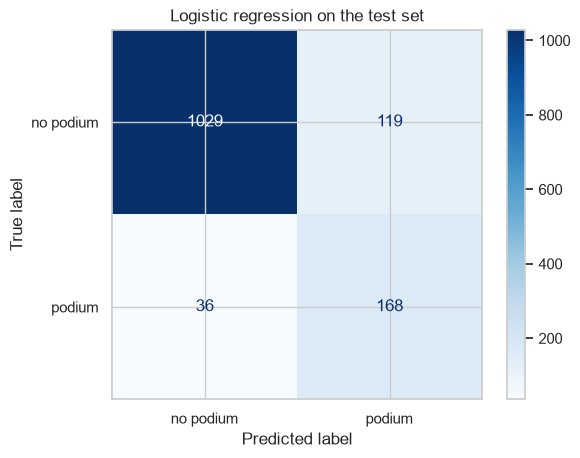

In [134]:
final_name = 'Logistic regression'
threshold = thresholds[final_name]

ConfusionMatrixDisplay.from_predictions(y_test, (p_test[final_name] >= threshold).astype(int), display_labels=['no podium', 'podium'], cmap='Blues')
plt.title('Logistic regression on the test set')
plt.show()

At the validation threshold of 0.27 the model finds 168 of the 204 test podiums (recall 0.82) and raises 119 false alarms (precision 0.59). The threshold is low because it maximises F1 with rare positives: the model names about 4 candidates per race (287 over 68 races) for 3 podium places. A user who wants fewer false alarms can raise the threshold and trade recall for precision along the curve above.

### 13.5 Feature groups

All experiments in this section use the same recipe: change one thing, train again, compare PR-AUC with the full pipeline. We use logistic regression because it is the final model, it trains in a second, and it gives the same result on every run. The same lines are repeated in every experiment, so they go in a function.

We show validation **and** test because validation is small (117 podiums). The test column is only reported; no choice is made from it.

In [135]:
def lr_pr_auc(X_a, y_a, X_b, X_c):
    # fit a logistic regression on X_a, return PR-AUC on validation (X_b) and test (X_c)
    m = LogisticRegression(max_iter=1000).fit(X_a, y_a)
    return [average_precision_score(y_val, m.predict_proba(X_b)[:, 1]), average_precision_score(y_test, m.predict_proba(X_c)[:, 1])]

full = lr_pr_auc(X_train_s, y_train, X_val_s, X_test_s)
full

[0.749433115088344, 0.725306826455218]

The six feature groups of section 9.11.

In [136]:
groups = {
    'grid': ['grid_position', 'grid_position_relative', 'front_row_start'],
    'qualifying': ['grid_penalty_places', 'qualifying_gap_to_pole_percent'],
    'driver form': ['driver_races_before', 'driver_podium_rate_last_5_races', 'driver_average_finish_last_5_races', 'driver_retirement_rate_last_10_races', 'driver_career_podium_rate', 'driver_podium_rate_at_circuit'],
    'constructor form': ['constructor_podium_rate_last_5_races', 'constructor_average_finish_last_5_races', 'constructor_mechanical_retirement_rate_last_10_races'],
    'standings': ['driver_points_share_before_race', 'driver_standing_position_before_race', 'driver_season_wins_before_race', 'constructor_points_share_before_race', 'constructor_standing_position_before_race'],
    'context': ['driver_age', 'home_race', 'season_progress', 'circuit_podium_rate_for_grid_group'],
}
sum(len(g) for g in groups.values())

23

### 13.6 Ablation: remove one group at a time

We remove one group of features at a time, train again, and see how much PR-AUC drops.

In [137]:
rows = []
for name, group in groups.items():
    keep = [f for f in features if f not in group]
    scores = lr_pr_auc(X_train_s[keep], y_train, X_val_s[keep], X_test_s[keep])
    rows.append([name, len(keep), full[0] - scores[0], full[1] - scores[1]])

ablation = pd.DataFrame(rows, columns=['removed group', 'features left', 'val drop', 'test drop']).set_index('removed group')
ablation.round(4)

,features left,val drop,test drop
removed group,,,
grid,20,0.0056,0.0191
qualifying,21,0.0097,-0.0001
driver form,17,0.0110,-0.0009
constructor form,20,-0.0020,0.0029
standings,18,-0.0027,0.0088
context,19,0.0149,-0.0002


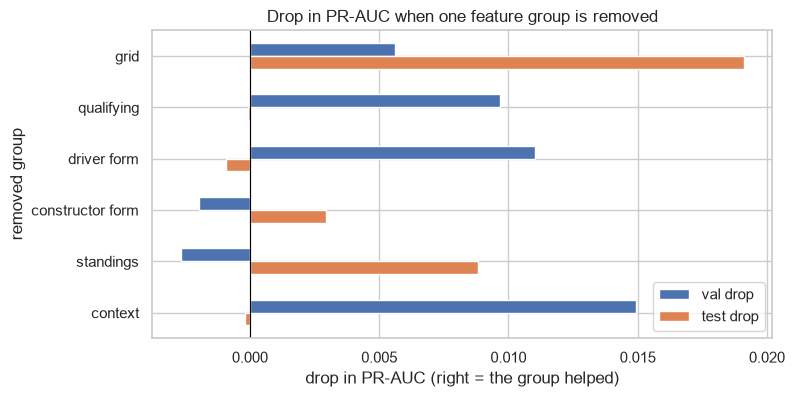

In [138]:
ablation[['val drop', 'test drop']].plot(kind='barh', figsize=(8, 4), title='Drop in PR-AUC when one feature group is removed')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('drop in PR-AUC (right = the group helped)')
plt.gca().invert_yaxis()
plt.show()

**No single group is essential.** Every drop is below 0.02, and several are slightly negative (the score went up without the group). With the noise level from section 12.4 (about 0.01), most of these bars cannot be told apart from zero.

- **Grid** is the only group that costs something on both validation and test (0.006 and 0.019), and it gives the largest drop on test.
- **Context**, **driver form** and **qualifying** cost about 0.01-0.015 on validation but nothing on test. **Standings** is the other way round (nothing on validation, 0.009 on test).
- The small drops do not mean the groups are useless. They overlap (section 10.2), so when one is removed the others fill in. For example, without the three grid features the model still has `circuit_podium_rate_for_grid_group`, which is built from the grid.

### 13.7 One group alone

Removing a group shows little when another group carries the same information. So we also turn it around: train on **one group alone**.

In [139]:
rows = []
for name, group in groups.items():
    rows.append([name] + lr_pr_auc(X_train_s[group], y_train, X_val_s[group], X_test_s[group]))
rows.append(['all features'] + full)

alone = pd.DataFrame(rows, columns=['only this group', 'val_pr_auc', 'test_pr_auc']).set_index('only this group')
alone.round(4)

,val_pr_auc,test_pr_auc
only this group,,
grid,0.6552,0.6582
qualifying,0.6393,0.6062
driver form,0.6455,0.5410
constructor form,0.5300,0.5145
standings,0.6506,0.5572
context,0.6301,0.5737
all features,0.7494,0.7253


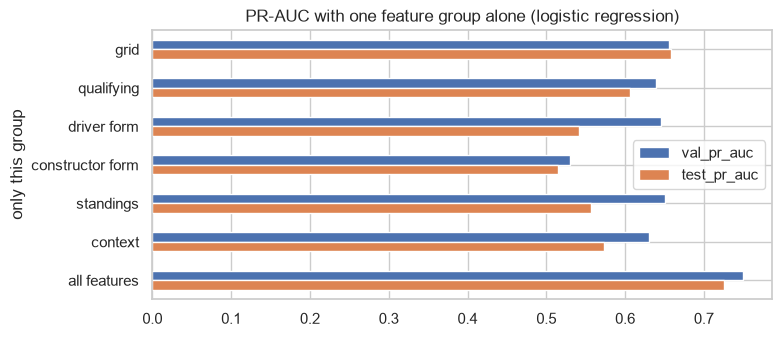

In [140]:
alone.plot(kind='barh', figsize=(8, 3.5), title='PR-AUC with one feature group alone (logistic regression)')
plt.gca().invert_yaxis()
plt.show()

This view is clearer. Every group alone is far below the full model (0.749 on validation, 0.725 on test), so **the gain comes from combining groups**, not from one of them.

- **Grid alone** is the strongest and the most stable (0.655 validation, 0.658 test).
- **Standings and driver form alone** are close to grid on validation but fall to 0.54-0.56 on test. They describe who has been strong so far, which says less in some seasons than in others.
- **Constructor form alone** is the weakest.

Together with the ablation: grid is the core signal, and the form, standings, qualifying and context groups each add a small, overlapping part on top of it. We keep all six groups.

### 13.8 Grid position: absolute, relative or both?

Section 9.2 kept both `grid_position` (1, 2, 3, ...) and `grid_position_relative` (grid divided by the number of starters) and left the choice to an experiment. We drop one at a time.

In [141]:
rows = [['both (our pipeline)'] + full]
for drop in ['grid_position', 'grid_position_relative']:
    keep = [f for f in features if f != drop]
    rows.append(['without ' + drop] + lr_pr_auc(X_train_s[keep], y_train, X_val_s[keep], X_test_s[keep]))

pd.DataFrame(rows, columns=['features', 'val_pr_auc', 'test_pr_auc']).round(4)

,features,val_pr_auc,test_pr_auc
0,both (our pipeline),0.7494,0.7253
1,without grid_position,0.7495,0.7252
2,without grid_position_relative,0.7498,0.7254


No difference: the three rows are within 0.0005 of each other. The two columns carry the same information (correlation 0.96), so the model does not need both, and neither version is better than the other. We keep both because dropping one gives no gain, but a smaller table could drop either one.

---
## 14. Pre-processing order experiments

Our pipeline is: **split → fill with the train median → scale with the train mean and std**. We change the order of these steps three times.

### 14.1 Split first, or pre-process first?


The wrong order is to fill and scale the whole table first and split afterwards. Then the medians, means and standard deviations are computed with the validation and test rows inside, which is a leak. First we look at how different the medians are.

In [142]:
medians_all = df[features].median()
pd.DataFrame({'train only': medians, 'all rows': medians_all})[medians != medians_all].round(3)

,train only,all rows
grid_position_relative,0.524,0.526
qualifying_gap_to_pole_percent,1.807,1.721
driver_races_before,70.000,82.000
driver_average_finish_last_5_races,11.400,11.200
driver_career_podium_rate,0.049,0.049
constructor_average_finish_last_5_races,11.400,11.300
constructor_points_share_before_race,0.124,0.130
driver_age,27.666,27.370


In [143]:
X_all = df[features].fillna(medians_all)
X_all_s = (X_all - X_all.mean()) / X_all.std()

a_wrong = lr_pr_auc(X_all_s[df['split'] == 'train'], y_train, X_all_s[df['split'] == 'val'], X_all_s[df['split'] == 'test'])
pd.DataFrame([['split first (our pipeline)'] + full, ['pre-process first'] + a_wrong], columns=['order', 'val_pr_auc', 'test_pr_auc']).round(4)

,order,val_pr_auc,test_pr_auc
0,split first (our pipeline),0.7494,0.7253
1,pre-process first,0.7500,0.7253


The scores are the same to about three decimals (0.749 against 0.750 on validation, 0.725 on test for both). The medians move a little, because validation and test are now 24% of the rows that are left (2,127 of 8,909), but a median or a mean is one number per feature and the model is not sensitive to small shifts in it.

So here the wrong order does not buy a better score. We still split first, because it is the only order that is honest: at prediction time the future races do not exist yet, and the inference function in section 16 can only use the training values.

### 14.2 Fill then scale, or scale then fill?

If we scale first, the mean and standard deviation are computed from the real values only. If we fill first, the filled rows are part of them, and many identical values shrink the standard deviation. Since we train from 2003, the qualifying gap has only 122 filled rows; `driver_podium_rate_at_circuit` has the most (1,622).

In [144]:
mean_b = train[features].mean()   # pandas skips the missing values
std_b = train[features].std()
pd.DataFrame({'std, fill first': std, 'std, scale first': std_b}).loc[['qualifying_gap_to_pole_percent', 'driver_podium_rate_at_circuit']].round(3)

,"std, fill first","std, scale first"
qualifying_gap_to_pole_percent,2.580,2.603
driver_podium_rate_at_circuit,0.217,0.236


In [145]:
Xb_train = (train[features] - mean_b) / std_b
medians_b = Xb_train.median()

b_other = lr_pr_auc(Xb_train.fillna(medians_b), y_train, ((val[features] - mean_b) / std_b).fillna(medians_b), ((test[features] - mean_b) / std_b).fillna(medians_b))
pd.DataFrame([['fill then scale (our pipeline)'] + full, ['scale then fill'] + b_other], columns=['order', 'val_pr_auc', 'test_pr_auc']).round(4)

,order,val_pr_auc,test_pr_auc
0,fill then scale (our pipeline),0.7494,0.7253
1,scale then fill,0.7496,0.7256


The standard deviations change only a little between the two orders (for example 0.217 against 0.236 for the circuit podium rate), and the scores are the same. For a logistic regression both orders give the same filled column, only stretched by a different constant, and the model absorbs that in the weight.

The order would matter for a method that fills from other columns (like nearest neighbours) or for a model that is sensitive to the exact scale. We keep fill then scale, because then the scaled table has exactly mean 0 and standard deviation 1.

### 14.3 "Was missing" flags before or after filling?

A flag column says "this value was missing". It only works if it is made **before** filling. After filling there is nothing left to flag:

In [146]:
flag_cols = ['qualifying_gap_to_pole_percent', 'driver_podium_rate_at_circuit', 'driver_standing_position_before_race']

print('flags made after filling: ', X_train[flag_cols].isna().sum().sum(), 'cells flagged')
print('flags made before filling:', train[flag_cols].isna().sum().sum(), 'cells flagged')

flags made after filling:  0 cells flagged
flags made before filling: 2227 cells flagged


Flags made after filling would be all 0, which is the same as our pipeline without flags. So we compare our pipeline with flags made before filling, for the three features with the most missing values.

In [147]:
Xc_train = X_train_s.copy()
Xc_val = X_val_s.copy()
Xc_test = X_test_s.copy()
for c in flag_cols:
    Xc_train[c + '_missing'] = train[c].isna().astype(int)
    Xc_val[c + '_missing'] = val[c].isna().astype(int)
    Xc_test[c + '_missing'] = test[c].isna().astype(int)

c_flags = lr_pr_auc(Xc_train, y_train, Xc_val, Xc_test)
pd.DataFrame([['no flags / flags after filling (our pipeline)'] + full, ['flags before filling'] + c_flags], columns=['order', 'val_pr_auc', 'test_pr_auc']).round(4)

,order,val_pr_auc,test_pr_auc
0,no flags / flags after filling (our pipeline),0.7494,0.7253
1,flags before filling,0.7467,0.7233


Here the order decides whether the step works at all: after filling, 0 cells can be flagged, before filling 2,227.

The flags themselves do not help: PR-AUC is slightly lower with them (0.747 against 0.749 on validation, 0.723 against 0.725 on test), again inside the noise. A missing circuit history or standings position says little about the podium. We keep the pipeline without extra flags.

**Summary of the three experiments:** the pre-processing order changes the numbers inside the table (medians, standard deviations, flags) but not the score of this model. We keep split → fill → scale because it is leak-free and is the order the inference function can repeat.

---
## 15. Explainability: what the model relies on, not what causes a podium

We explain the final model, the logistic regression.

**Important:** everything in this section describes **what the model relies on**, not what causes a podium. A high importance for a feature means the predictions change a lot when that feature changes. It does not prove that changing it in the real world would change the result. For example, the model leans on the grid position, but a slow car moved to pole by hand would not become a podium car.

### 15.1 Global: permutation importance

We shuffle one feature in the validation set, which breaks its link with the target, and measure how much PR-AUC drops. A big drop means the model needs that feature. Each feature is shuffled 10 times.

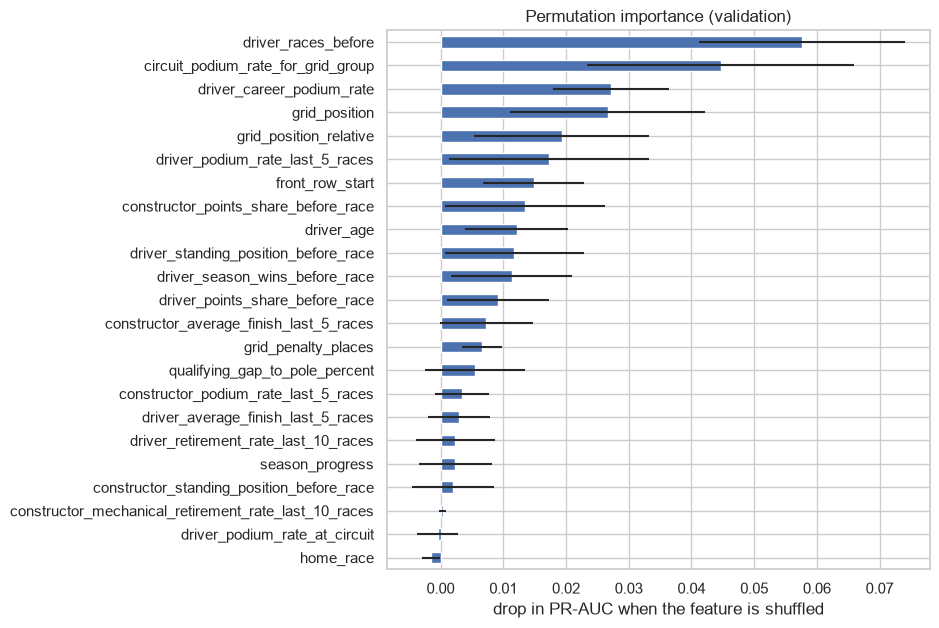

In [148]:
perm = permutation_importance(lr, X_val_s, y_val, scoring='average_precision', n_repeats=10, random_state=42)

perm_table = pd.DataFrame({'drop in PR-AUC': perm.importances_mean, 'std': perm.importances_std}, index=features).sort_values('drop in PR-AUC')
perm_table['drop in PR-AUC'].plot(kind='barh', xerr=perm_table['std'], figsize=(7, 7), title='Permutation importance (validation)')
plt.xlabel('drop in PR-AUC when the feature is shuffled')
plt.show()

No single feature dominates. `driver_races_before` costs the most when shuffled (about 0.06 PR-AUC), then `circuit_podium_rate_for_grid_group` (about 0.045), and `driver_career_podium_rate` and `grid_position` (about 0.027 each). The black lines (the spread over the 10 shuffles) are wide, and the bottom half of the features is at zero.

A feature at zero is not proven useless. When several features carry the same information, shuffling one leaves the others to do the job, so each looks small. The grid information is spread over four columns (`grid_position`, `grid_position_relative`, `front_row_start` and the circuit rate per grid group), so together the grid is still the strongest signal, as the ablation in section 13.6 showed.

### 15.2 Global: SHAP

SHAP splits each prediction into one contribution per feature. A positive value pushed this prediction towards podium, a negative value pushed it away (in log-odds, the scale the logistic regression works in).

The beeswarm shows every validation row as a dot, with the features sorted by their mean contribution. Red = high value of the feature, blue = low value.

Background dataset has 6782 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=6782 when initializing the masker.


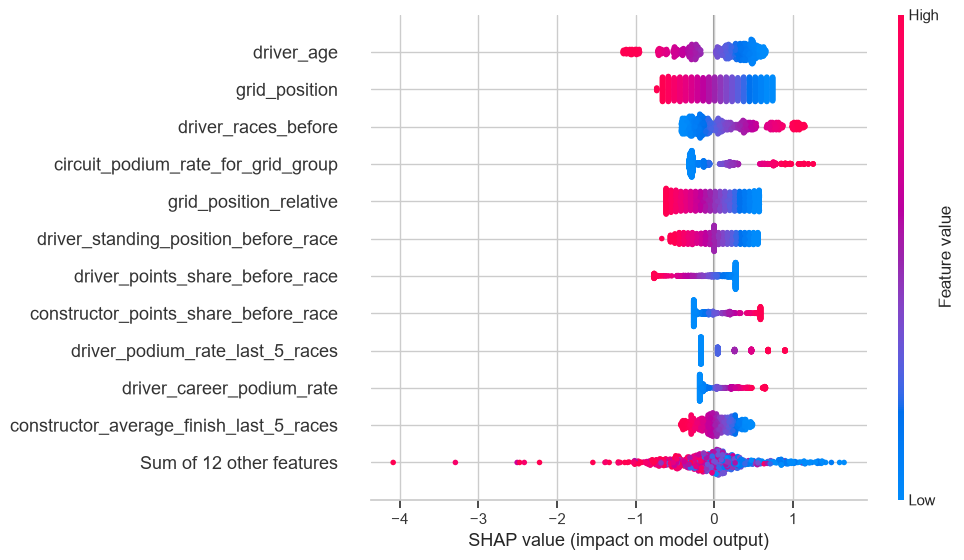

In [149]:
explainer = shap.LinearExplainer(lr, X_train_s)
shap_values = explainer(X_val_s)
shap_values.data = X_val.values   # show the real values in the plots, not the scaled ones

shap_values.shape

shap.plots.beeswarm(shap_values, max_display=12)

The beeswarm sorts features by their average contribution, so it does not have to match the permutation order exactly.

- `grid_position` and `grid_position_relative`: red dots (a start far back) are on the left, blue dots (a start at the front) on the right. The model lowers the podium probability as the grid number grows.
- `driver_age` and `driver_races_before` point in opposite directions: young drivers (blue) and drivers with many races (red) are pushed up. The two columns move together (older drivers have more races), so the model uses them as a pair: many races **for one's age** means a top driver who got into F1 early. Read on their own they look strange, which is a limit of reading weights of correlated features.
- `circuit_podium_rate_for_grid_group`: high values (a grid group that often reaches the podium at this circuit) push up.
- "Sum of 12 other features" has a few red dots far on the left. These are mostly drivers with a huge gap to pole: a linear model keeps subtracting for every extra percent, so outliers get extreme values. This is a limit of the model.

Again: these plots show how **the model** uses the features. They are not effects on the race.

### 15.3 Local: LIME for one prediction

We take one row: the driver on pole in the last validation race. LIME makes many small random changes to this row, asks the model for a prediction on each, and fits a small linear model on those to see which features matter around this one row.

In [150]:
i = np.where((val['raceId'] == val['raceId'].iloc[-1]) & (val['grid_position'] == 1))[0][0]

print('predicted probability:', round(lr.predict_proba(X_val_s.iloc[[i]])[0, 1], 3), '| real podium:', y_val.iloc[i])
val.iloc[i][['raceId', 'driverId', 'year', 'round', 'grid_position', 'driver_podium_rate_last_5_races', 'constructor_podium_rate_last_5_races', 'driver_points_share_before_race']]

predicted probability: 0.958 | real podium: 1


raceId                                  1073
driverId                                 830
year                                    2021
round                                     22
grid_position                              1
driver_podium_rate_last_5_races          1.0
constructor_podium_rate_last_5_races     0.7
driver_points_share_before_race          1.0
Name: 23200, dtype: object

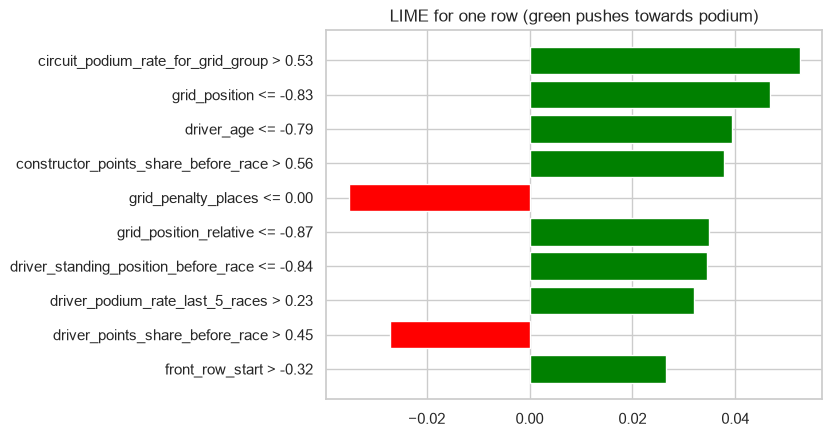

In [151]:
lime_explainer = LimeTabularExplainer(X_train_s.values, feature_names=features, class_names=['no podium', 'podium'], mode='classification', random_state=42)
lime_exp = lime_explainer.explain_instance(X_val_s.iloc[i].values, lambda a: lr.predict_proba(pd.DataFrame(a, columns=features)), num_features=10)

lime_exp.as_pyplot_figure()
plt.title('LIME for one row (green pushes towards podium)')
plt.show()

The row is the pole sitter of the 2021 season finale (round 22). The model gives 0.96, and the driver did finish on the podium.

The longest green bars are the circuit rate for this grid group, the grid position, the driver's age and the constructor's points share: the same kind of features that lead the global explanations. Two small red bars (no grid penalty, and the driver points share) pull the other way. The conditions are in scaled units because the model works on the scaled table (`grid_position <= -0.83` means a start near the front).

This explains why the model said 0.96. It does not say that these features caused the podium.

---
## 16. Inference function

### 16.1 The function

One function that takes the pre-race features of one driver in one race and returns the podium probability and the yes/no decision. It repeats the training pipeline with the values learned from train: fill with `medians`, scale with `mean` and `std`, predict with the final model, and compare with the validation `threshold`.

A feature that is not in the record is treated as missing.

In [152]:
def predict_podium(record):
    row = pd.DataFrame([record], columns=features).astype(float)   # features not in the record become NaN
    row = row.fillna(medians)
    row = (row - mean) / std
    p = lr.predict_proba(row)[0, 1]
    return round(float(p), 3), int(p >= threshold)

### 16.2 A complete record

We take a test row that has every feature.

In [153]:
record = test.dropna()[features].iloc[0].to_dict()
record

predict_podium(record)

(0.272, 1)

### 16.3 A partially-missing record

The same driver, but we do not know the qualifying gap, the history at this circuit or the standings position.

In [154]:
partial = record.copy()
del partial['qualifying_gap_to_pole_percent']
del partial['driver_podium_rate_at_circuit']
partial['driver_standing_position_before_race'] = None

predict_podium(partial)

(0.38, 1)

The function works on both records. With the three values missing it fills in the train medians, and the probability moves from 0.27 to 0.38, still above the threshold of 0.27.

The filled values are "typical" values, not the real ones, so a prediction from a partial record is less reliable. Here the real record is from round 2 of 2022, when this driver was 19th in the standings after scoring no points in round 1. The median standings position that replaced it is much better, and that pushes the probability up more than losing the good qualifying gap and the circuit history pushes it down.

---
## 17. Summary and limitations

- **Cleaning (once):** 26,759 result rows → 24,571 driver-race rows (duplicates from shared drives, the Indianapolis 500, drivers who never started, and grid 0 with 0 laps removed). Every primary key is unique and every foreign key reconciles. The grain (`raceId`, `driverId`) is unique. The questions, the features and the experiments all filter this one cleaned table.
- **Data-engineering questions:** front-row conversion rose from 68.3% (2003–2013) to 76.2% (2014–2024) and the circuit ranking changed (rank correlation 0.36). There is no home advantage once grid is controlled (odds ratio 0.96, 95% CI 0.81–1.14). The Enstone team (Lotus F1 / Renault / Alpine) has the highest mechanical-retirement rate in both periods, and the overall rate fell from 9.5% to 5.9%.
- **Features:** 24 pre-race features in six groups (grid, qualifying, driver form, constructor form, standings before the race, context). Form uses `shift()` so a row only sees earlier races, and standings come from the previous round. The model uses 23 of them: `has_qualifying_data` is 1 on every row from 2003.
- **Training seasons:** 1950, 1994 and 2003 as start years are tied on validation (0.746, 0.752, 0.749), so we train on **2003-2019** (6,782 rows): the most recent seasons, raced under rules closest to the test years, with complete qualifying data.
- **Models:** logistic regression (baseline), random forest and a shallow neural network, on the same rows and features. The final model is the baseline, logistic regression (validation PR-AUC 0.749, test PR-AUC 0.725, test ROC-AUC 0.937). It is first on validation and test, the network is close to it inside the seed noise, and neither complex model earned its extra complexity.
- **Experiments:** no single feature group is essential, the gain comes from combining them; the pre-processing order changes the table but not the score.
- **Explainability:** the grid information (spread over four columns), the driver's experience and career podium rate, and the circuit rate per grid group lead. These show what the model relies on, **not** what causes a podium.
- **Limitations:** era sensitivity (the training seasons 2003-2019 still span several rule eras, and older seasons were not used), a small validation set (117 podiums), renamed teams losing their history, correlated features (age and experience) that are hard to read one by one, the shared-drive grid, and `season_progress` in 2020.